In [210]:
import matplotlib.pyplot as plt
import pandas as pd
from belfast.target_definition import Target
from belfast.target_utils import query_data
import belfast.mcmc_utils as mcmc
import emcee
import numpy as np
from scipy.stats import norm
import os
from belfast.isochrone_utils import load_regularized_Mini_interpolator

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [161]:
interp_func, interp_u, interp_u_to_outputs, interp_u_bounds, interp_variable_list, interp_output_list, data, = load_regularized_Mini_interpolator(
    '../data/isochrones/regular_Mini_grids/regularized_Mini_grid_1e6_2001e6yr_step10e6_linear_isochrones_MS_with_inc.npz',
    force_float64=False
)

Loaded regularized Mini grid.
grid_type: with_inc
interp_variable_list: ['Mini', 'logAge', 'MH', 'omega_ini', 'Inclination']
interp_output_list: ['Mass', 'omega', 'Req', 'Rpol', 'G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
grid_outputs shape: (1392, 201, 12, 7, 11, 12)
grid_bounds shape: (201, 12, 7, 11, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
save_float32: True
read_all_at_once: True
total grid memory: 11835.89 MB (11.56 GB)


In [167]:
interp_func_pars, interp_u_pars, interp_u_to_outputs_pars, interp_u_bounds_pars, interp_variable_list_pars, interp_output_list_pars, data_pars, = load_regularized_Mini_interpolator(
    '../data/isochrones/regular_Mini_grids/regularized_Mini_grid_1e6_2001e6yr_step10e6_linear_isochrones_MS_without_inc.npz',
    force_float64=False
)

Loaded regularized Mini grid.
grid_type: without_inc
interp_variable_list: ['Mini', 'logAge', 'MH', 'omega_ini']
interp_output_list: ['Mass', 'omega', 'logL', 'Req', 'Rpol']
grid_outputs shape: (1392, 201, 12, 7, 5)
grid_bounds shape: (201, 12, 7, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
save_float32: True
read_all_at_once: True
total grid memory: 448.42 MB (0.44 GB)


In [162]:
import numpy as np
import pandas as pd
from scipy.special import logsumexp
import emcee


# ============================================================
# Basic helper
# ============================================================

def distance_modulus_from_parallax(parallax_mas):
    return 10.0 - 5.0 * np.log10(parallax_mas)


def gaussian_lnprior(x, mu, sigma):
    return -0.5 * ((x - mu) / sigma) ** 2


# ============================================================
# Isochrone evaluation
# ============================================================

def evaluate_nonrot_isochrone(
    interp_func,
    logAge,
    MH,
    Mini_grid=None,
    omega_ini=1e-8,
    Inclination=1e-8,
):
    if Mini_grid is None:
        Mini_grid = np.arange(1.0, 5.0 + 0.01, 0.01)

    x = np.column_stack([
        Mini_grid,
        np.full_like(Mini_grid, logAge, dtype=float),
        np.full_like(Mini_grid, MH, dtype=float),
        np.full_like(Mini_grid, omega_ini, dtype=float),
        np.full_like(Mini_grid, Inclination, dtype=float),
    ])

    y = interp_func(x)

    output_cols = [
        "Mass", "omega", "Req", "Rpol",
        "G", "G_BP", "G_RP",
        "B_T", "V_T",
        "J", "H", "Ks",
    ]

    return Mini_grid, pd.DataFrame(y, columns=output_cols)


# ============================================================
# One-star likelihood
# ============================================================

def lnlike_one_star_to_isochrone(
    row,
    iso_df,
    band_list,
    mag_col_suffix="_mag",
    err_col_suffix="_err",
    parallax_col="parallax",
    extinction_dict=None,
    Mini_prior=None,
):
    parallax = row[parallax_col]

    if not np.isfinite(parallax) or parallax <= 0:
        return -np.inf

    dm = distance_modulus_from_parallax(parallax)

    chi2 = np.zeros(len(iso_df), dtype=float)

    n_used = 0

    for band in band_list:
        mag_col = f"{band}{mag_col_suffix}"
        err_col = f"{band}{err_col_suffix}"

        if mag_col not in row.index or err_col not in row.index:
            continue

        obs_mag = row[mag_col]
        obs_err = row[err_col]

        if not np.isfinite(obs_mag) or not np.isfinite(obs_err) or obs_err <= 0:
            continue

        A_band = 0.0
        if extinction_dict is not None:
            A_band = extinction_dict.get(band, 0.0)

        model_app_mag = iso_df[band].values + dm + A_band

        valid = np.isfinite(model_app_mag)

        chi2_i = np.full(len(iso_df), np.inf)
        chi2_i[valid] = ((obs_mag - model_app_mag[valid]) / obs_err) ** 2

        chi2 += chi2_i
        n_used += 1

    if n_used == 0:
        return -np.inf

    lnlike_Mini = -0.5 * chi2

    if Mini_prior is not None:
        lnlike_Mini = lnlike_Mini + Mini_prior(iso_df["Mass"].values)

    return logsumexp(lnlike_Mini) - np.log(len(lnlike_Mini))


# ============================================================
# Cluster likelihood
# ============================================================

def lnlike_cluster(
    theta,
    df_cluster,
    interp_func,
    band_list,
    Mini_grid=None,
    age_prior=None,
    MH_prior=None,
    extinction_mode="none",
):
    logAge, MH = theta

    if not np.isfinite(logAge) or not np.isfinite(MH):
        return -np.inf

    lp = 0.0

    if age_prior is not None:
        lp += age_prior(logAge)

    if MH_prior is not None:
        lp += MH_prior(MH)

    if not np.isfinite(lp):
        return -np.inf

    Mini_grid, iso_df = evaluate_nonrot_isochrone(
        interp_func=interp_func,
        logAge=logAge,
        MH=MH,
        Mini_grid=Mini_grid,
        omega_ini=1e-8,
        Inclination=1e-8,
    )

    total_lnlike = 0.0

    for _, row in df_cluster.iterrows():

        extinction_dict = None

        if extinction_mode == "A550_same_for_all_bands":
            A550 = row.get("A550", 0.0)
            extinction_dict = {band: A550 for band in band_list}

        lnlike_i = lnlike_one_star_to_isochrone(
            row=row,
            iso_df=iso_df,
            band_list=band_list,
            parallax_col="parallax",
            extinction_dict=extinction_dict,
        )

        if not np.isfinite(lnlike_i):
            continue

        total_lnlike += lnlike_i

    return lp + total_lnlike


# ============================================================
# Sampling logAge and MH
# ============================================================

def run_cluster_age_MH_sampling(
    df_cluster,
    interp_func,
    band_list=("G", "G_BP", "G_RP"),
    Mini_grid=None,
    age_prior_mu=None,
    age_prior_sigma=None,
    MH_prior_mu=None,
    MH_prior_sigma=None,
    init_logAge=8.8,
    init_MH=0.0,
    n_walkers=32,
    n_steps=3000,
    burnin=500,
):
    if Mini_grid is None:
        Mini_grid = np.arange(1.0, 5.0 + 0.01, 0.01)

    age_prior = None
    if age_prior_mu is not None and age_prior_sigma is not None:
        age_prior = lambda x: gaussian_lnprior(x, age_prior_mu, age_prior_sigma)

    MH_prior = None
    if MH_prior_mu is not None and MH_prior_sigma is not None:
        MH_prior = lambda x: gaussian_lnprior(x, MH_prior_mu, MH_prior_sigma)

    def log_prob(theta):
        return lnlike_cluster(
            theta=theta,
            df_cluster=df_cluster,
            interp_func=interp_func,
            band_list=list(band_list),
            Mini_grid=Mini_grid,
            age_prior=age_prior,
            MH_prior=MH_prior,
            extinction_mode="none",
        )

    ndim = 2

    p0 = np.array([init_logAge, init_MH])
    p0 = p0 + 1e-3 * np.random.randn(n_walkers, ndim)

    sampler = emcee.EnsembleSampler(
        n_walkers,
        ndim,
        log_prob,
    )

    sampler.run_mcmc(p0, n_steps, progress=True)

    samples = sampler.get_chain(discard=burnin, flat=True)

    logAge_samples = samples[:, 0]
    MH_samples = samples[:, 1]
    age_samples_myr = 10 ** logAge_samples / 1e6

    age_q16, age_q50, age_q84 = np.percentile(age_samples_myr, [16, 50, 84])
    MH_q16, MH_q50, MH_q84 = np.percentile(MH_samples, [16, 50, 84])

    print(
        f"Age = {age_q50:.1f} "
        f"+{age_q84 - age_q50:.1f} "
        f"-{age_q50 - age_q16:.1f} Myr"
    )

    print(
        f"[M/H] = {MH_q50:.3f} "
        f"+{MH_q84 - MH_q50:.3f} "
        f"-{MH_q50 - MH_q16:.3f}"
    )

    return sampler, samples



In [163]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Wrapper for interp_func
# ============================================================
def model_func_example(
    Mini,
    logAge,
    MH,
    omega_ini=1e-8,
    inclination=1e-8,
):
    x = np.array([
        Mini,
        logAge,
        MH,
        omega_ini,
        inclination,
    ], dtype=float)

    y = interp_func(x)

    return {
        "Mass": y[0],
        "omega": y[1],
        "Req": y[2],
        "Rpol": y[3],
        "G": y[4],
        "G_BP": y[5],
        "G_RP": y[6],
        "B_T": y[7],
        "V_T": y[8],
        "J": y[9],
        "H": y[10],
        "Ks": y[11],
    }


def evaluate_isochrone_grid(
    model_func,
    Mini_grid,
    logAge,
    MH,
    omega_ini=1e-8,
    inclination=1e-8,
):


    x = np.column_stack([
        Mini_grid,
        np.full_like(Mini_grid, logAge, dtype=float),
        np.full_like(Mini_grid, MH, dtype=float),
        np.full_like(Mini_grid, omega_ini, dtype=float),
        np.full_like(Mini_grid, inclination, dtype=float),
    ])

    # If your interp_func supports batch input, this is faster.
    y = interp_func(x)
    if logAge < 7:
        y=np.array([np.inf]*12)
    return {
        "Mass": y[:, 0],
        "omega": y[:, 1],
        "Req": y[:, 2],
        "Rpol": y[:, 3],
        "G": y[:, 4],
        "G_BP": y[:, 5],
        "G_RP": y[:, 6],
        "B_T": y[:, 7],
        "V_T": y[:, 8],
        "J": y[:, 9],
        "H": y[:, 10],
        "Ks": y[:, 11],
    }


# ============================================================
# Helper
# ============================================================
def abs_mag_from_parallax(mag, parallax_mas, A=0.0):
    return mag + 5.0 * np.log10(parallax_mas) - 10.0 - A


def abs_mag_err_from_parallax(mag_err, parallax_mas, parallax_err, A_err=0.0):
    return np.sqrt(
        mag_err**2
        + (5.0 / np.log(10.0) * parallax_err / parallax_mas)**2
        + A_err**2
    )


def posterior_summary(x):
    q16, q50, q84 = np.percentile(x, [16, 50, 84])
    return q16, q50, q84


def format_pm(q16, q50, q84, digits=1):
    return rf"{q50:.{digits}f}$^{{+{q84-q50:.{digits}f}}}_{{-{q50-q16:.{digits}f}}}$"


# ============================================================
# CMD plot function
# ============================================================
def plot_cluster_cmd_fit(
    df_cluster,
    posterior_samples,
    Mini_grid=None,
    fit_systems=("Gaia",),
    omega_ini=1e-8,
    inclination=1e-8,
    n_posterior_lines=100,
    random_seed=42,
    A_col="A550",
    A_err_col="A550_err",
    save_prefix=None,
    show=True,
):
    """
    posterior_samples:
        shape (N, 2)
        column 0 = logAge
        column 1 = MH
    """

    if Mini_grid is None:
        Mini_grid = np.arange(1.0, 5.0 + 0.01, 0.01)

    CMD_CONFIGS = {
        "Gaia": {
            "x_bands": ("G_BP", "G_RP"),
            "y_band": "G",
            "x_mag_cols": ("G_BP_mag", "G_RP_mag"),
            "x_err_cols": ("G_BP_err", "G_RP_err"),
            "y_mag_col": "G_mag",
            "y_err_col": "G_err",
            "xlabel": r"$M_{G_{\rm BP}} - M_{G_{\rm RP}}\;(\mathrm{mag})$",
            "ylabel": r"$M_G\;(\mathrm{mag})$",
        },
        "2MASS": {
            "x_bands": ("J", "Ks"),
            "y_band": "J",
            "x_mag_cols": ("J_mag", "Ks_mag"),
            "x_err_cols": ("J_err", "Ks_err"),
            "y_mag_col": "J_mag",
            "y_err_col": "J_err",
            "xlabel": r"$M_J - M_{K_s}\;(\mathrm{mag})$",
            "ylabel": r"$M_J\;(\mathrm{mag})$",
        },
        "Tycho2": {
            "x_bands": ("B_T", "V_T"),
            "y_band": "V_T",
            "x_mag_cols": ("B_T_mag", "V_T_mag"),
            "x_err_cols": ("B_T_err", "V_T_err"),
            "y_mag_col": "V_T_mag",
            "y_err_col": "V_T_err",
            "xlabel": r"$M_{B_T} - M_{V_T}\;(\mathrm{mag})$",
            "ylabel": r"$M_{V_T}\;(\mathrm{mag})$",
        },
    }

    posterior_samples = np.asarray(posterior_samples, dtype=float)

    logAge_samples = posterior_samples[:, 0]
    MH_samples = posterior_samples[:, 1]
    age_samples_myr = 10.0**logAge_samples / 1e6

    age_16, age_50, age_84 = posterior_summary(age_samples_myr)
    MH_16, MH_50, MH_84 = posterior_summary(MH_samples)

    age_label = format_pm(age_16, age_50, age_84, digits=1)
    MH_label = format_pm(MH_16, MH_50, MH_84, digits=3)

    median_label = (
        rf"median: age = {age_label} Myr, "
        rf"$[\mathrm{{M/H}}]$ = {MH_label}"
    )

    rng = np.random.default_rng(random_seed)
    n_draw = min(n_posterior_lines, len(posterior_samples))
    draw_idx = rng.choice(len(posterior_samples), size=n_draw, replace=False)

    figs = {}
    axes = {}

    for system in fit_systems:
        cfg = CMD_CONFIGS[system]

        required_cols = [
            cfg["x_mag_cols"][0],
            cfg["x_mag_cols"][1],
            cfg["x_err_cols"][0],
            cfg["x_err_cols"][1],
            cfg["y_mag_col"],
            cfg["y_err_col"],
            "parallax",
            "parallax_err",
        ]

        if A_col is not None and A_col in df_cluster.columns:
            required_cols.append(A_col)

        if A_err_col is not None and A_err_col in df_cluster.columns:
            required_cols.append(A_err_col)

        df = df_cluster.dropna(subset=required_cols).copy()

        if len(df) == 0:
            print(f"No valid stars for {system}.")
            continue

        A = df[A_col].values if A_col is not None and A_col in df.columns else 0.0
        A_err = df[A_err_col].values if A_err_col is not None and A_err_col in df.columns else 0.0

        y_obs = abs_mag_from_parallax(
            df[cfg["y_mag_col"]].values,
            df["parallax"].values,
            A=A,
        )

        y_err = abs_mag_err_from_parallax(
            df[cfg["y_err_col"]].values,
            df["parallax"].values,
            df["parallax_err"].values,
            A_err=A_err,
        )

        x1_obs = abs_mag_from_parallax(
            df[cfg["x_mag_cols"][0]].values,
            df["parallax"].values,
            A=A,
        )

        x2_obs = abs_mag_from_parallax(
            df[cfg["x_mag_cols"][1]].values,
            df["parallax"].values,
            A=A,
        )

        x1_err = abs_mag_err_from_parallax(
            df[cfg["x_err_cols"][0]].values,
            df["parallax"].values,
            df["parallax_err"].values,
            A_err=A_err,
        )

        x2_err = abs_mag_err_from_parallax(
            df[cfg["x_err_cols"][1]].values,
            df["parallax"].values,
            df["parallax_err"].values,
            A_err=A_err,
        )

        x_obs = x1_obs - x2_obs
        x_err = np.sqrt(x1_err**2 + x2_err**2)

        fig, ax = plt.subplots(figsize=(8, 5))

        ax.errorbar(
            x_obs,
            y_obs,
            xerr=x_err,
            yerr=y_err,
            fmt="o",
            ms=4,
            color="black",
            ecolor="black",
            elinewidth=1,
            capsize=0,
            alpha=0.9,
            zorder=5,
            label="observed stars",
        )

        # Posterior isochrone draws
        for idx in draw_idx:
            logAge_i = logAge_samples[idx]
            MH_i = MH_samples[idx]

            iso_i = evaluate_isochrone_grid(
                model_func=model_func_example,
                Mini_grid=Mini_grid,
                logAge=logAge_i,
                MH=MH_i,
                omega_ini=omega_ini,
                inclination=inclination,
            )

            x_model_i = iso_i[cfg["x_bands"][0]] - iso_i[cfg["x_bands"][1]]
            y_model_i = iso_i[cfg["y_band"]]

            valid = np.isfinite(x_model_i) & np.isfinite(y_model_i)

            ax.plot(
                x_model_i[valid],
                y_model_i[valid],
                color="orange",
                alpha=0.08,
                linewidth=1.0,
                zorder=1,
            )

        # Median isochrone
        iso_med = evaluate_isochrone_grid(
            model_func=model_func_example,
            Mini_grid=Mini_grid,
            logAge=np.median(logAge_samples),
            MH=np.median(MH_samples),
            omega_ini=omega_ini,
            inclination=inclination,
        )

        x_model_med = iso_med[cfg["x_bands"][0]] - iso_med[cfg["x_bands"][1]]
        y_model_med = iso_med[cfg["y_band"]]

        valid = np.isfinite(x_model_med) & np.isfinite(y_model_med)

        ax.plot(
            x_model_med[valid],
            y_model_med[valid],
            color="black",
            linewidth=2.2,
            label=median_label,
            zorder=10,
        )

        ax.invert_yaxis()
        ax.grid(True, linestyle="--", alpha=0.4)

        ax.set_xlabel(cfg["xlabel"], fontsize=16)
        ax.set_ylabel(cfg["ylabel"], fontsize=16)
        ax.tick_params(axis="both", labelsize=13)
        ax.legend(fontsize=11, loc="best")

        fig.tight_layout()

        if save_prefix is not None:
            fig.savefig(
                f"{save_prefix}_{system}_CMD_fit.pdf",
                bbox_inches="tight",
            )

        figs[system] = fig
        axes[system] = ax

    if show:
        plt.show()
    else:
        plt.close("all")

    return figs, axes

In [ ]:
df_cluster = pd.read_csv("/Users/ziyinggu/Programming/Projects/belfast-astro/data/clusters/hyades_targets.csv")

sampler, samples = run_cluster_age_MH_sampling(
    df_cluster=df_cluster,
    interp_func=interp_func,
    # band_list=("G", "G_BP", "G_RP"),          # Gaia
    # band_list=("J", "H", "Ks"),             # 2MASS
    # band_list=("B_T", "V_T"),               # Tycho-2
    band_list=("G", "G_BP", "G_RP", "J", "H", "Ks", "B_T", "V_T"),

    Mini_grid=np.arange(1.0, 5.0 + 0.01, 0.01),

    age_prior_mu=8.8,
    age_prior_sigma=1,

    MH_prior_mu=0.09,
    MH_prior_sigma=0.07,

    init_logAge=np.log10(700)+6,
    init_MH=0.09,

    n_walkers=32,
    n_steps=300,
    burnin=100,
)

In [ ]:
# Gaia

In [ ]:
import corner
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Corner plot
# ============================================================
logAge_samples = samples[:, 0]
MH_samples = samples[:, 1]
age_samples_myr = 10**logAge_samples / 1e6

corner_samples = np.column_stack([
    age_samples_myr,
    MH_samples,
])

fig = corner.corner(
    corner_samples,
    labels=[r"Age (Myr)", r"$[\mathrm{M/H}]$"],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_fmt=".3f",
)

# fig.savefig("./data/clusters/figures/hyades_nonrot_cluster_corner.pdf", bbox_inches="tight")
plt.show()

In [ ]:
figs, axes = plot_cluster_cmd_fit(
    df_cluster=df_cluster,
    posterior_samples=samples,
    Mini_grid=np.arange(1.0, 5.0 + 0.01, 0.01),
    fit_systems=("Gaia",),
    omega_ini=1e-8,
    inclination=1e-8,
    n_posterior_lines=100,
    save_prefix="./data/clusters/figures/hyades_nonrot_cluster_fit",
    show=True,
)

In [ ]:
# 2MASS

In [ ]:
import corner
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Corner plot
# ============================================================
logAge_samples = samples[:, 0]
MH_samples = samples[:, 1]
age_samples_myr = 10**logAge_samples / 1e6

corner_samples = np.column_stack([
    age_samples_myr,
    MH_samples,
])

fig = corner.corner(
    corner_samples,
    labels=[r"Age (Myr)", r"$[\mathrm{M/H}]$"],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_fmt=".3f",
)

# fig.savefig("./data/clusters/figures/hyades_nonrot_cluster_corner.pdf", bbox_inches="tight")
plt.show()

In [ ]:
figs, axes = plot_cluster_cmd_fit(
    df_cluster=df_cluster,
    posterior_samples=samples,
    Mini_grid=np.arange(1.0, 5.0 + 0.01, 0.01),
    fit_systems=("Gaia",),
    omega_ini=1e-8,
    inclination=1e-8,
    n_posterior_lines=100,
    save_prefix="./data/clusters/figures/hyades_nonrot_cluster_fit",
    show=True,
)

In [ ]:
# Tycho-2

In [ ]:
import corner
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Corner plot
# ============================================================
logAge_samples = samples[:, 0]
MH_samples = samples[:, 1]
age_samples_myr = 10**logAge_samples / 1e6

corner_samples = np.column_stack([
    age_samples_myr,
    MH_samples,
])

fig = corner.corner(
    corner_samples,
    labels=[r"Age (Myr)", r"$[\mathrm{M/H}]$"],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_fmt=".3f",
)

# fig.savefig("./data/clusters/figures/hyades_nonrot_cluster_corner.pdf", bbox_inches="tight")
plt.show()

In [ ]:
figs, axes = plot_cluster_cmd_fit(
    df_cluster=df_cluster,
    posterior_samples=samples,
    Mini_grid=np.arange(1.0, 5.0 + 0.01, 0.01),
    fit_systems=("Gaia",),
    omega_ini=1e-8,
    inclination=1e-8,
    n_posterior_lines=100,
    save_prefix="./data/clusters/figures/hyades_nonrot_cluster_fit",
    show=True,
)

In [565]:
import numpy as np
import matplotlib.pyplot as plt


MODEL_OUTPUTS = [
    "Mass", "omega", "Req", "Rpol",
    "G", "G_BP", "G_RP", "B_T", "V_T", "J", "H", "Ks"
]


def eval_isochrone(
    model_interp,
    Mini_grid,
    logAge,
    MH=0.01,
    omega_ini=0.0,
    Inclination=0.0,
):
    X = np.column_stack([
        Mini_grid,
        np.full_like(Mini_grid, logAge, dtype=float),
        np.full_like(Mini_grid, MH, dtype=float),
        np.full_like(Mini_grid, omega_ini, dtype=float),
        np.full_like(Mini_grid, Inclination, dtype=float),
    ])

    Y = model_interp(X)

    iso = {}
    for i, name in enumerate(MODEL_OUTPUTS):
        iso[name] = Y[:, i]

    iso["Mini"] = Mini_grid
    iso["logAge"] = logAge
    iso["age_Myr"] = 10 ** (logAge - 6)
    iso["MH"] = MH
    iso["omega_ini"] = omega_ini
    iso["Inclination"] = Inclination

    return iso


def get_cmd_xy(iso, color="G_BP-G_RP", mag="G"):
    b1, b2 = color.split("-")
    x = iso[b1] - iso[b2]
    y = iso[mag]
    return x, y


def _make_age_color_dict(ages_sorted, age_colors=None):
    if age_colors is None:
        age_colors = [
            "tab:blue", "tab:orange", "tab:red", "black",
            "tab:purple", "tab:brown", "tab:green",
        ]

    return {
        age: age_colors[i % len(age_colors)]
        for i, age in enumerate(ages_sorted)
    }


def _alpha_from_inclination(
    inc,
    inc_min=0.0,
    inc_max=1.57,
    alpha_min=0.35,
    alpha_max=1.0,
):
    t = (inc - inc_min) / (inc_max - inc_min)
    t = np.clip(t, 0.0, 1.0)
    return alpha_min + t * (alpha_max - alpha_min)


def _interp_point_at_mass(iso, x, y, mass_value, mass_key="Mini"):
    mass_arr = np.asarray(iso[mass_key], dtype=float)

    valid = (
        np.isfinite(mass_arr)
        & np.isfinite(x)
        & np.isfinite(y)
    )

    mass_arr = mass_arr[valid]
    x_arr = x[valid]
    y_arr = y[valid]

    if len(mass_arr) < 2:
        return None

    order = np.argsort(mass_arr)
    mass_arr = mass_arr[order]
    x_arr = x_arr[order]
    y_arr = y_arr[order]

    if mass_value < np.nanmin(mass_arr) or mass_value > np.nanmax(mass_arr):
        return None

    x_m = np.interp(mass_value, mass_arr, x_arr)
    y_m = np.interp(mass_value, mass_arr, y_arr)

    return x_m, y_m


def plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(1.0, 5.0 + 0.01, 0.01),
    ages_Myr=(100, 180, 345, 700),
    MH=0.01,
    omega_ini_list=(0.0, 0.8),
    inclination_list=(0.0, 0.524, 1.047, 1.57),
    color="G_BP-G_RP",
    mag="G",
    obs=None,
    obs_err=None,
    title=None,
    figsize=(7, 8),
    age_colors=("tab:blue", "tab:orange", "tab:red", "black"),
    rot_alpha_range=(0.35, 1.0),
    nonrot_alpha=0.75,
    rot_lw=2.2,
    nonrot_lw=1.8,
    inc_alpha_min=0.0,
    inc_alpha_max=1.57,
    grid_alpha=0.25,
    legend_fontsize=8,
    xlim=None,
    ylim=None,

    # mass marker settings
    mass_marks=(1.5, 2.0, 2.5, 3.0),
    mass_key="Mini",
    mass_marker_cycle=("s", "^", "v", "x", "o"),
    mass_marker_size=55,
    mass_text=True,
    mass_text_iso_index=-1,
    mass_text_dx=0.025,
    mass_text_dy=0.035,
    mass_text_fontsize=9,

    save_name=None,
):
    fig, ax = plt.subplots(figsize=figsize)

    ages_Myr = np.asarray(ages_Myr, dtype=float)
    ages_sorted = np.sort(ages_Myr)

    age_to_base_color = _make_age_color_dict(
        ages_sorted,
        age_colors=list(age_colors),
    )

    alpha_min, alpha_max = rot_alpha_range

    plotted_isochrones = []

    for age_Myr in ages_sorted:
        logAge = np.log10(age_Myr) + 6
        base_color = age_to_base_color[age_Myr]

        for omega_ini in omega_ini_list:

            if np.isclose(omega_ini, 0.0):
                inc_list_this = [0.0]
                linestyle = "--"
                lw = nonrot_lw
            else:
                inc_list_this = inclination_list
                linestyle = "-"
                lw = rot_lw

            for inc in inc_list_this:
                iso = eval_isochrone(
                    model_interp=interp_func,
                    Mini_grid=Mini_grid,
                    logAge=logAge,
                    MH=MH,
                    omega_ini=omega_ini,
                    Inclination=inc,
                )

                x, y = get_cmd_xy(iso, color=color, mag=mag)
                valid = np.isfinite(x) & np.isfinite(y)

                if np.isclose(omega_ini, 0.0):
                    plot_alpha = nonrot_alpha
                    label = f"{age_Myr:.0f} Myr, non-rot"
                else:
                    plot_alpha = _alpha_from_inclination(
                        inc,
                        inc_min=inc_alpha_min,
                        inc_max=inc_alpha_max,
                        alpha_min=alpha_min,
                        alpha_max=alpha_max,
                    )
                    label = (
                        f"{age_Myr:.0f} Myr, "
                        f"ωini={omega_ini:.2f}, "
                        f"i={inc:.3f}, "
                        f"α={plot_alpha:.2f}"
                    )

                ax.plot(
                    x[valid],
                    y[valid],
                    color=base_color,
                    lw=lw,
                    ls=linestyle,
                    alpha=plot_alpha,
                    label=label,
                )

                mass_points = []

                if mass_marks is not None:
                    for j, m in enumerate(mass_marks):
                        point = _interp_point_at_mass(
                            iso=iso,
                            x=x,
                            y=y,
                            mass_value=m,
                            mass_key=mass_key,
                        )

                        if point is None:
                            continue

                        x_m, y_m = point
                        marker = mass_marker_cycle[j % len(mass_marker_cycle)]

                        ax.scatter(
                            x_m,
                            y_m,
                            s=mass_marker_size,
                            marker=marker,
                            color=base_color,
                            alpha=plot_alpha,
                            zorder=5,
                        )

                        mass_points.append((m, x_m, y_m, marker))

                plotted_isochrones.append({
                    "age_Myr": age_Myr,
                    "omega_ini": omega_ini,
                    "Inclination": inc,
                    "x": x,
                    "y": y,
                    "iso": iso,
                    "mass_points": mass_points,
                    "color": base_color,
                })

    if mass_text and mass_marks is not None and len(plotted_isochrones) > 0:
        ref_iso = plotted_isochrones[mass_text_iso_index]

        for j, item in enumerate(ref_iso["mass_points"]):
            m, x_m, y_m, marker = item

            ax.text(
                x_m + mass_text_dx,
                y_m + mass_text_dy * (j - 0.5 * len(ref_iso["mass_points"])),
                f"{m:.2f} $M_\\odot$",
                color=ref_iso["color"],
                fontsize=mass_text_fontsize,
                va="center",
                ha="right",
            )

    if obs is not None:
        c1, c2 = color.split("-")
        obs_x = obs[c1] - obs[c2]
        obs_y = obs[mag]

        if obs_err is not None:
            obs_xerr = np.sqrt(obs_err[c1] ** 2 + obs_err[c2] ** 2)
            obs_yerr = obs_err[mag]
        else:
            obs_xerr = None
            obs_yerr = None

        ax.errorbar(
            obs_x,
            obs_y,
            xerr=obs_xerr,
            yerr=obs_yerr,
            fmt="*",
            ms=14,
            capsize=3,
            color="black",
            label="Observed target",
            zorder=10,
        )

    # plt.scatter(0.642 - 0.456, 0.577, marker="*", s=100, color="black", alpha=0.5, label="Mock target (2.25 Msun)")
    # plt.scatter(1.355 - 1.159, 1.287, marker="D", s=100, color="black", alpha=0.5, label="Mock target (2.00 Msun)")
    # plt.scatter(2.11474257 - 1.90933357, 2.05340857, marker="D", s=100, color="black", alpha=0.5, label="HIP 8847")

    ax.invert_yaxis()
    ax.set_xlabel(color)
    ax.set_ylabel(mag)
    xmin, xmax = ax.get_xlim()
    xpad = 0.15 * (xmax - xmin)
    ax.set_xlim(xmin - xpad, xmax)

    if title is None:
        title = f"CMD isochrones, [M/H]={MH}"

    ax.set_title(title)
    ax.legend(fontsize=legend_fontsize)
    ax.grid(alpha=grid_alpha)

    if xlim is not None:
        plt.xlim(xlim)
    if ylim is not None:
        plt.ylim(ylim)

    plt.tight_layout()
    if save_name is not None:
        plt.savefig(save_name)
    return fig, ax

In [ ]:
import astropy.constants as ct
import numpy as np
Mass, omega, Req, Rpol = interp_func([2., np.log10(700)+6, 0.09, 0.8, np.deg2rad(30)])[:, :4].flatten()
M_abs = interp_func([2, np.log10(700)+6, 0.09, 0.8, np.deg2rad(30)])[:, 4:].flatten()
omega_angular = omega * np.sqrt(ct.GM_sun*Mass/(ct.R_sun * 1.5 * Rpol)**3)
omega_keplerian = np.sqrt(ct.GM_sun * Mass / (ct.R_sun * Req)**3)
omega_k = omega_angular / omega_keplerian
omega_k = omega_k.value
v_critical = np.sqrt(ct.GM_sun * Mass / (ct.R_sun * 1.5 * Rpol)).to('km/s').value
vtaneq = (omega_angular * Req * ct.R_sun).to('km/s').value
vsini = vtaneq * np.sin(np.deg2rad(30))
print(f'M_obs = {np.round(M_abs, 3)}')
print(f'vsini = {vsini}')

In [ ]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(1.5, 7.0 + 0.005, 0.005),
    ages_Myr=(600, 700, 800),
    MH=0.01,
    omega_ini_list=(0.0, 0.8),
    inclination_list=(0.0, 0.524, 1.047, 1.57),
    # color="G_BP-G_RP",
    # mag="G",
    color='B_T-V_T',
    mag='V_T',
    # color="J-Ks",
    # mag="H",
    rot_alpha_range=(0.1, 1.0),
    nonrot_alpha=0.7,
    mass_marks=(1.5, 2.0, 2.5, 3.0),
    mass_marker_cycle=("s", "^", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.03,
    mass_text_dy=0.0,
)

In [ ]:
interp_u([1.9, np.log10(1200)+6, 0.09, 0.8, 0.2])

In [ ]:
interp_u([1.9, np.log10(1200)+6, 0.09, 0.000001, 0.2])

In [ ]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(1.0, 3.0 + 0.005, 0.005),
    ages_Myr=(1000, 1100),
    MH=0.02,
    omega_ini_list=(0.0, 0.8),
    inclination_list=(0.0, 0.524, 1.047, 1.57),
    color="G_BP-G_RP",
    mag="G",
    # color='B_T-V_T',
    # mag='V_T',
    # color="J-Ks",
    # mag="H",
    rot_alpha_range=(0.1, 1.0),
    nonrot_alpha=0.7,
    mass_marks=(1.7, ),
    mass_marker_cycle=("^", "s", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.03,
    mass_text_dy=0.0,
    save_name='Mock Hyades star CMD.pdf',
)

In [ ]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(1.77, 2.4 + 0.005, 0.005),
    ages_Myr=( 130,),
    # ages_Myr=(180, 345),
    # ages_Myr=(600, 700, 800),
    MH=0.0,
    omega_ini_list=(0.0, 0.8),
    inclination_list=(0.0, 1.57*0.5, 1.57),
    color="G_BP-G_RP",
    mag="G",
    # color='B_T-V_T',
    # mag='V_T',
    # color="J-Ks",
    # mag="H",
    rot_alpha_range=(0.4, 1.0),
    nonrot_alpha=0.7,
    mass_marks=( 2.0, ),
    mass_marker_cycle=("s", "^", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.02,
    mass_text_dy=-0.02,
    # xlim=[-0.05, 0.05],
    # figsize=[20, 20],
)

In [ ]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(3.9, 4.1 + 0.005, 0.005),
    ages_Myr=(100, 130, 160),
    # ages_Myr=(180, 345),
    # ages_Myr=(600, 700, 800),
    MH=0.01,
    omega_ini_list=(0.0, 0.99),
    inclination_list=(0.0, 1.57*0.5, 1.57),
    color="G_BP-G_RP",
    mag="G",
    # color='B_T-V_T',
    # mag='V_T',
    # color="J-Ks",
    # mag="H",
    rot_alpha_range=(0.4, 1.0),
    nonrot_alpha=0.7,
    mass_marks=(4.0, ),
    mass_marker_cycle=("s", "^", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.02,
    mass_text_dy=-0.02,
    # xlim=[-0.05, 0.05],
    # figsize=[10, 10],
)

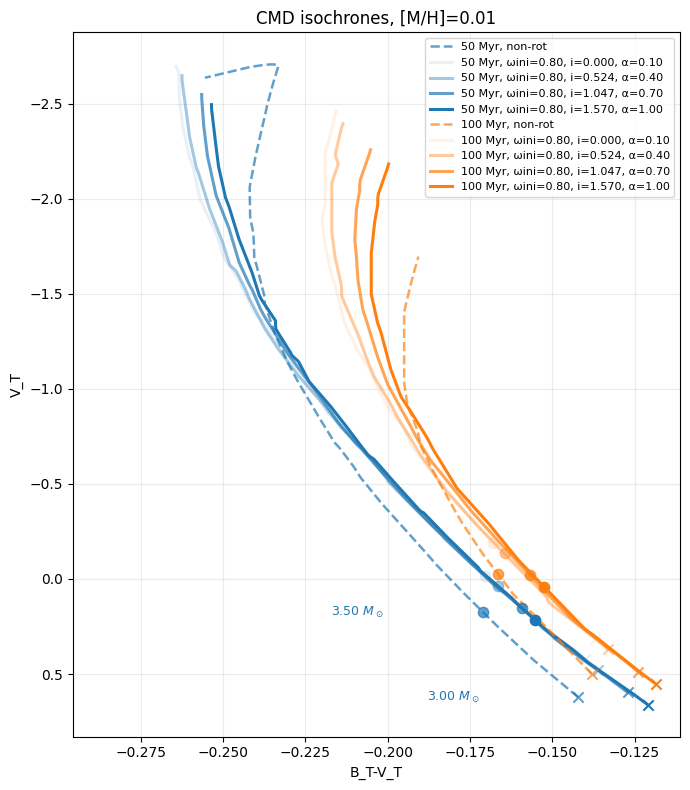

In [592]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(3, 7.0 + 0.005, 0.005),
    # ages_Myr=(100, 150, 200),
    ages_Myr=(50, 100, ),
    MH=0.01,
    omega_ini_list=(0.0, 0.8),
    inclination_list=(0.0, 0.524, 1.047, 1.57),
    # color="G_BP-G_RP",
    # mag="G",
    color='B_T-V_T',
    mag='V_T',
    # color="J-Ks",
    # mag="H",
    rot_alpha_range=(0.1, 1.0),
    nonrot_alpha=0.7,
    mass_marks=(1.5, 2.0, 2.5, 3.0, 3.5),
    mass_marker_cycle=("s", "^", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.03,
    mass_text_dy=0.0,
)

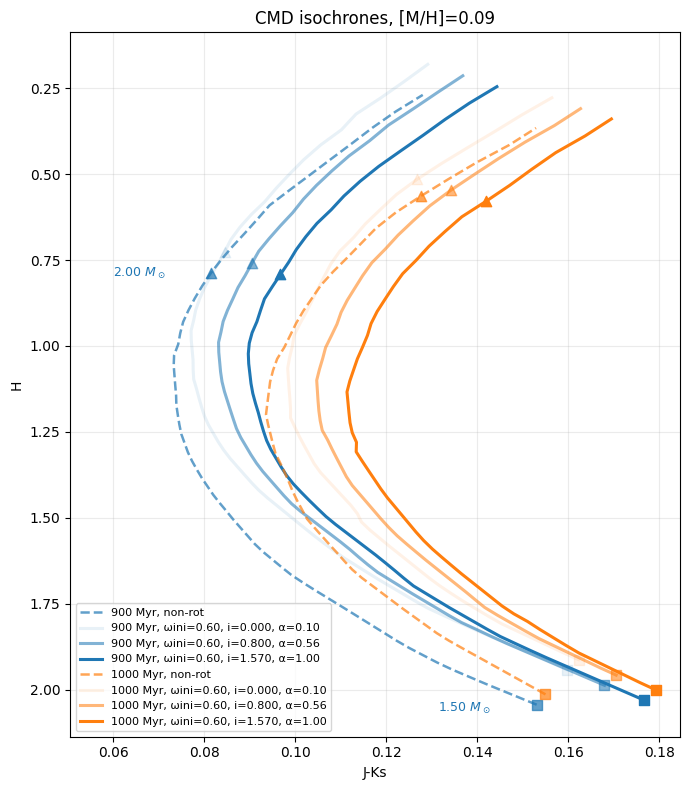

In [590]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(1.5, 4.0 + 0.01, 0.01),
    ages_Myr=(900, 1000),
    # ages_Myr=(100, 200),
    MH=0.09,
    omega_ini_list=(0.0, 0.6),
    inclination_list=(0.0, 0.8, 1.57),
    # color="G_BP-G_RP",
    # mag="G",
    # color='B_T-V_T',
    # mag='V_T',
    color="J-Ks",
    mag="H",
    rot_alpha_range=(0.1, 1.0),
    nonrot_alpha=0.7,
    mass_marks=(1.5, 2.0, 2.5, 3.0, 3.5),
    mass_marker_cycle=("s", "^", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.01,
    mass_text_dy=-0.01,
)

In [658]:
import numpy as np
import matplotlib.pyplot as plt


EVOL_INPUTS = ["Mini", "logAge", "MH", "omega_ini"]
EVOL_OUTPUTS = ["Mass", "omega", "logL", "Req", "Rpol"]


def evaluate_evolution_track(
    interp_func,
    Mini,
    age_Myr_grid,
    MH=0.0,
    omega_ini=0.0,
):
    """
    Evaluate one evolutionary track at fixed Mini, MH, and omega_ini.

    Input order:
        ['Mini', 'logAge', 'MH', 'omega_ini']

    Output order:
        ['Mass', 'omega', 'logL', 'Req', 'Rpol']

    logAge is log10(age / yr).
    """

    age_Myr_grid = np.asarray(age_Myr_grid, dtype=float)
    logAge_grid = np.log10(age_Myr_grid) + 6.0

    X = np.column_stack([
        np.full_like(logAge_grid, Mini, dtype=float),
        logAge_grid,
        np.full_like(logAge_grid, MH, dtype=float),
        np.full_like(logAge_grid, omega_ini, dtype=float),
    ])

    Y = interp_func(X)

    track = {}
    for i, name in enumerate(EVOL_OUTPUTS):
        track[name] = Y[:, i]

    track["Mini"] = np.full_like(age_Myr_grid, Mini, dtype=float)
    track["age_Myr"] = age_Myr_grid
    track["logAge"] = logAge_grid
    track["MH"] = np.full_like(age_Myr_grid, MH, dtype=float)
    track["omega_ini"] = np.full_like(age_Myr_grid, omega_ini, dtype=float)

    return track


def _make_mass_color_dict(mass_list, mass_colors=None):
    if mass_colors is None:
        mass_colors = [
            "tab:blue",
            "tab:orange",
            "tab:red",
            "black",
            "tab:purple",
            "tab:brown",
            "tab:green",
        ]

    return {
        mass: mass_colors[i % len(mass_colors)]
        for i, mass in enumerate(mass_list)
    }


def _alpha_from_omega(
    omega_ini,
    omega_min=0.0,
    omega_max=1.0,
    alpha_min=0.25,
    alpha_max=1.0,
):
    """
    Larger omega_ini -> darker / less transparent.
    omega_ini = omega_min gives alpha_min.
    omega_ini = omega_max gives alpha_max.
    """

    t = (omega_ini - omega_min) / (omega_max - omega_min)
    t = np.clip(t, 0.0, 1.0)

    return alpha_min + t * (alpha_max - alpha_min)


def plot_evolution_L_R_tracks(
    interp_func,
    Mini_list=(1.5, 2.0, 2.5),
    age_Myr_grid=np.linspace(10, 2000, 5000),
    MH=0.0,
    omega_ini_list=(0.0, 0.2, 0.4, 0.6, 0.8),
    mass_colors=None,
    omega_alpha_range=(0.25, 1.0),
    omega_alpha_min=0.0,
    omega_alpha_max=1.0,
    nonrot_alpha=0.5,
    nonrot_omega_value=0.0,
    figsize=(9, 5.5),
    lw=2.0,
    nonrot_lw=1.8,
    grid_alpha=0.25,
    legend_fontsize=8,
    title=None,
    xlim=None,
    ylim=None,
    save_name=None,
):
    """
    Plot three horizontal evolutionary panels:
        x-axis: age in Myr
        y-axis: logL, Req, Rpol

    Same Mini uses same color.
    For rotating models, larger omega_ini has larger alpha.
    For non-rotating omega_ini=0, use dashed line with alpha=0.5 by default.
    """

    Mini_list = list(Mini_list)
    omega_ini_list = list(omega_ini_list)

    mass_to_color = _make_mass_color_dict(
        Mini_list,
        mass_colors=mass_colors,
    )

    fig, axes = plt.subplots(
        3,
        1,
        figsize=figsize,
        sharex=True,
        gridspec_kw={"hspace": 0.08},
    )

    y_info = [
        ("logL", "L"),
        ("Req", r"$R_{\rm eq}$"),
        ("Rpol", r"$R_{\rm pol}$"),
    ]

    for Mini in Mini_list:
        base_color = mass_to_color[Mini]

        for omega_ini in omega_ini_list:

            is_nonrot = np.isclose(omega_ini, nonrot_omega_value)

            if is_nonrot:
                line_alpha = nonrot_alpha
                linestyle = "--"
                line_lw = nonrot_lw
            else:
                line_alpha = _alpha_from_omega(
                    omega_ini,
                    omega_min=omega_alpha_min,
                    omega_max=omega_alpha_max,
                    alpha_min=omega_alpha_range[0],
                    alpha_max=omega_alpha_range[1],
                )
                linestyle = "-"
                line_lw = lw

            track = evaluate_evolution_track(
                interp_func=interp_func,
                Mini=Mini,
                age_Myr_grid=age_Myr_grid,
                MH=MH,
                omega_ini=omega_ini,
            )

            label = (
                rf"$M_{{\rm ini}}={Mini:.2f}\,M_\odot$, "
                rf"$\omega_{{\rm ini}}={omega_ini:.2f}$"
            )

            for ax, (key, ylabel) in zip(axes, y_info):
                y = track[key]
                valid = np.isfinite(track["age_Myr"]) & np.isfinite(y)
                plot_x = track["age_Myr"][valid]
                plot_y = y[valid]
                if key == 'logL':
                    plot_y = 10**plot_y

                ax.plot(
                    plot_x,
                    plot_y,
                    color=base_color,
                    alpha=line_alpha,
                    lw=line_lw,
                    ls=linestyle,
                    label=label if key == "logL" else None,
                )

                ax.set_ylabel(ylabel)
                ax.grid(alpha=grid_alpha)

    # x_over = [180, 345]
    # y_rot_over = [10**1.292, 1.866001, 1.672001]
    # y_non_rot_over = [10**1.341452, 1.836019, 1.836012]
    # s=100
    # axes[0].scatter(x_over[0], y_rot_over[0], s=s, marker="+", color='red', label='rot')
    # axes[1].scatter(x_over[0], y_rot_over[1], s=s, marker="+", color='red')
    # axes[2].scatter(x_over[0], y_rot_over[2], s=s, marker="+", color='red')
    # axes[0].scatter(x_over[1], y_non_rot_over[0], s=s, marker="x", color='orange', label='non-rot')
    # axes[1].scatter(x_over[1], y_non_rot_over[1], s=s, marker="x", color='orange')
    # axes[2].scatter(x_over[1], y_non_rot_over[2], s=s, marker="x", color='orange')

    axes[-1].set_xlabel("Age [Myr]")

    if title is None:
        title = rf"Evolution tracks, [M/H] = {MH:.3f}"

    axes[0].set_title(title)

    axes[0].legend(
        fontsize=legend_fontsize,
        ncol=2,
        frameon=True,
    )

    if xlim is not None:
        plt.xlim(xlim)
    if ylim is not None:
        plt.ylim(ylim)
    plt.tight_layout()
    if save_name is not None:
        plt.savefig(save_name)
    return fig, axes

In [ ]:
!open .

/var/folders/xc/rw1jkm1x0_1bhxz5h8s2_d200000gn/T/ipykernel_67311/2235369890.py:228: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


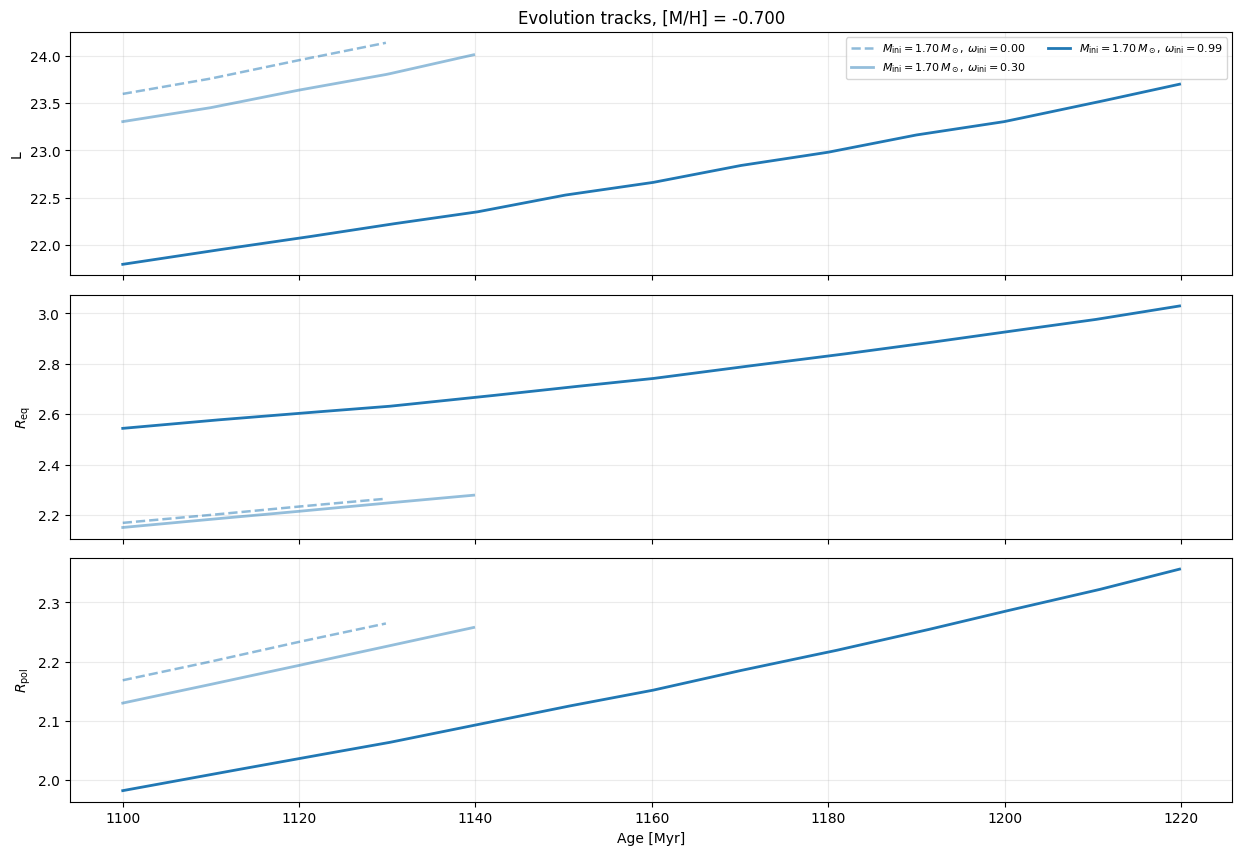

In [673]:
fig, axes = plot_evolution_L_R_tracks(
    interp_func=interp_func_pars,
    Mini_list=(1.7,),
    # age_Myr_grid=np.linspace(100, 5000, 901),
    age_Myr_grid=np.linspace(1100, 2000, 1901),
    MH=-0.7,
    omega_ini_list=(0.0, 0.3, 0.99),
    omega_alpha_range=(0.25, 1.0),
    nonrot_alpha=0.5,
    figsize=(15, 10),
    # xlim=[800, 1200],
#     save_name='evolution of L, Req and Rpol (2 and 2.2.25 M_sun).pdf',
)

/var/folders/xc/rw1jkm1x0_1bhxz5h8s2_d200000gn/T/ipykernel_67311/1733909718.py:228: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


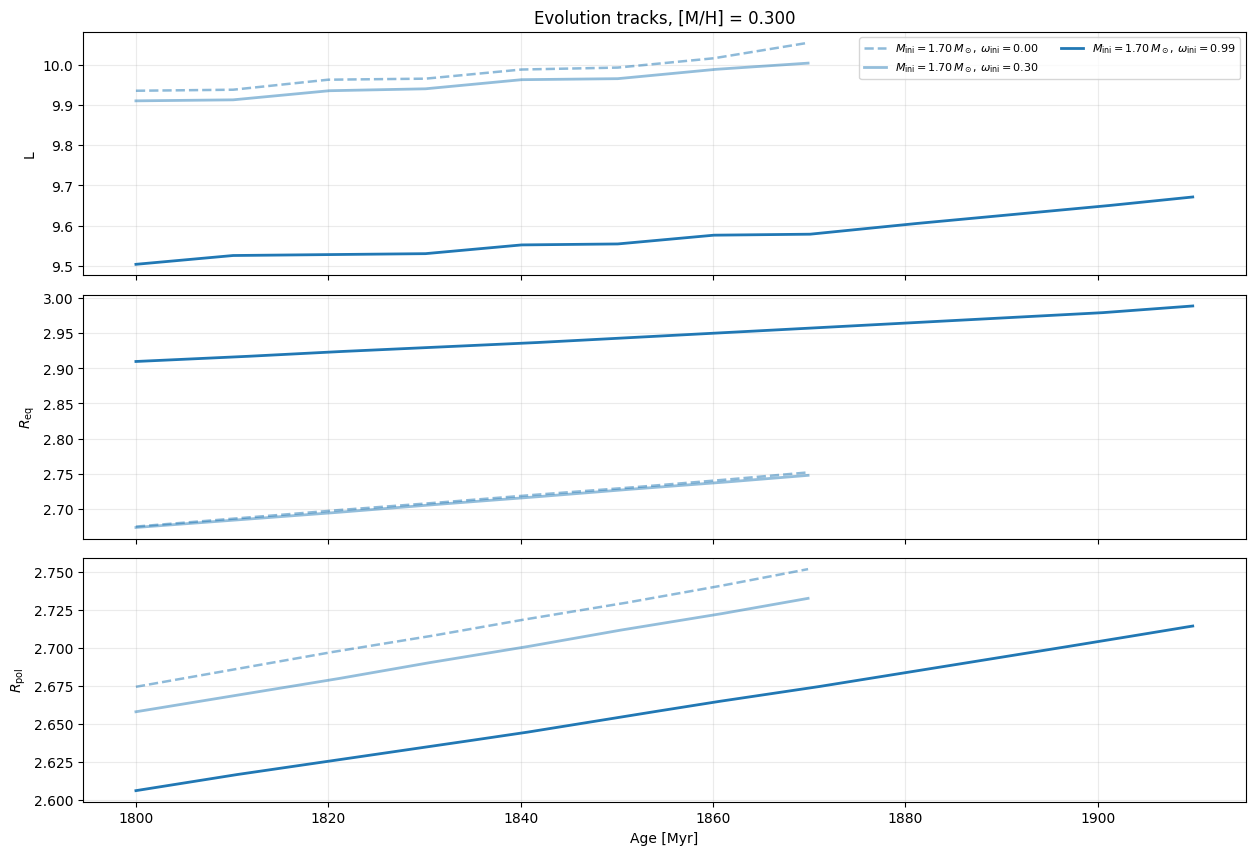

In [641]:
fig, axes = plot_evolution_L_R_tracks(
    interp_func=interp_func_pars,
    Mini_list=(1.7,),
    # age_Myr_grid=np.linspace(100, 5000, 901),
    age_Myr_grid=np.linspace(1800, 2000, 1901),
    MH=0.30,
    omega_ini_list=(0.0, 0.3, 0.99),
    omega_alpha_range=(0.25, 1.0),
    nonrot_alpha=0.5,
    figsize=(15, 10),
    # xlim=[800, 1200],
#     save_name='evolution of L, Req and Rpol (2 and 2.2.25 M_sun).pdf',
)

In [45]:
import numpy as np
from lib.isochrone_utils import PARSECv2_collect_data
from matplotlib import pyplot as plt
from matplotlib.patches import Polygon

In [33]:
df = PARSECv2_collect_data('/Users/ziyinggu/Downloads/omega0.80_output603625566772.dat.gz', label_list='all')

100%|██████████| 1/1 [00:06<00:00,  6.82s/it]


In [339]:
10**(df['logAge'].unique()[10:100:10]-6)

array([109.99931989, 119.9996557 , 129.99899654, 140.00063322,
       149.99956514, 160.00000639, 170.00042222, 179.99896172,
       189.99842462])

In [35]:
# df['logAge'].unique()

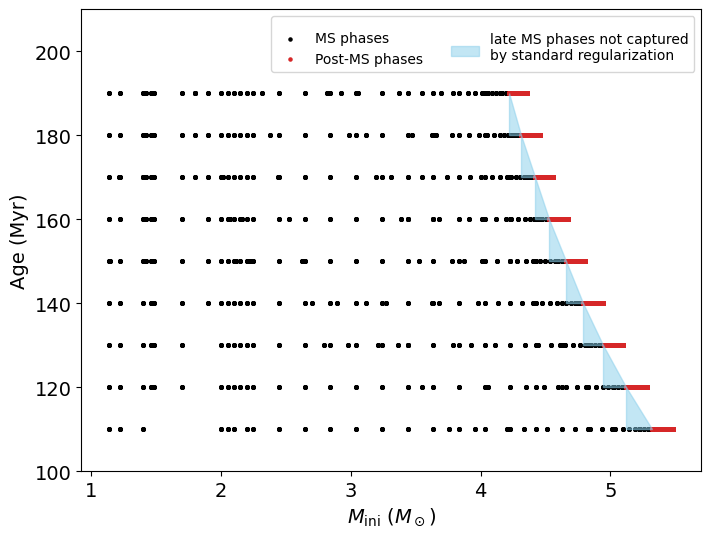

In [345]:
c = 0
fz=14
marker_size = 5
# logAge_list = df['logAge'].unique()[10::30]
logAge_list = df['logAge'].unique()[10:100:10]
min_ms = []
max_ms = []
max_post = []
plt.figure(figsize=[8, 6])
for logAge_i in logAge_list:
    Mini_0 = df[(df['logAge']==logAge_i)  & (df['label']==0)]['Mini']
    Mini_1 = df[(df['logAge']==logAge_i)  & (df['label']==1)]['Mini']
    Mini_2 = df[(df['logAge']==logAge_i)  & (df['label']>=2)]['Mini']
    min_ms.append(np.min(Mini_1))
    max_ms.append(np.max(Mini_1))
    max_post.append(np.max(Mini_2))
    if c == 0:
        label_0 = 'Pre-MS phases'
        label_1 = 'MS phases'
        label_2 = 'Post-MS phases'
    else:
        label_0 = None
        label_1 = None
        label_2 = None

    # plt.scatter(Mini_0, np.ones_like(Mini_0) * 10**(logAge_i-6), s=marker_size, c='tab:blue', label=label_0)
    plt.scatter(Mini_1, np.ones_like(Mini_1) * 10**(logAge_i-6), s=marker_size, c='black', label=label_1)
    plt.scatter(Mini_2, np.ones_like(Mini_2) * 10**(logAge_i-6), s=marker_size, c='tab:red', label=label_2)
    c+=1

for i in range(len(logAge_list)-1):
    x = [max_ms[i], max_ms[i+1], max_ms[i+1]]
    y = [10**(logAge_list[i]-6), 10**(logAge_list[i]-6), 10**(logAge_list[i+1]-6)]
    if i == 0:
        label_fill='late MS phases not captured\nby standard regularization'
    else:
        label_fill=None
    poly = Polygon(list(zip(x, y)), closed=True, color='skyblue', alpha=0.5, label=label_fill)
    plt.gca().add_patch(poly)

leg = plt.legend(ncol=2, fontsize=10)

# 第三个 legend 向下平移
texts = leg.get_texts()
handles = leg.legend_handles  # 如果报错，看下面兼容写法

texts[2].set_y(texts[2].get_position()[1] - 10)
handles[2].set_y(handles[2].get_y() - 10)
# plt.legend(fontsize=10)

plt.ylim([100, 210])
# plt.xlim([1,6])
plt.ylabel('Age (Myr)', fontsize=fz)
plt.xlabel(r'$M_{\rm ini}$ ($M_\odot$)', fontsize=fz)
plt.tick_params(axis='both', labelsize=fz)
plt.savefig('Mini-age relation.pdf', bbox_inches='tight', pad_inches=0.02)


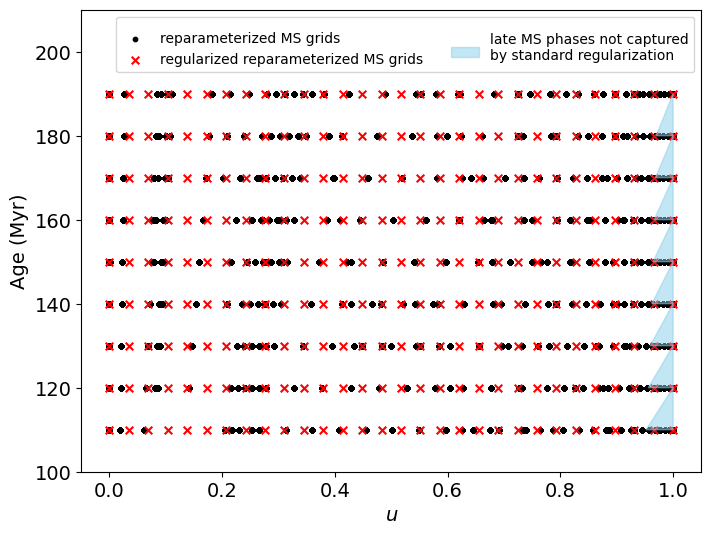

In [348]:
c = 0
fz = 14
marker_size = 10
# logAge_list = df['logAge'].unique()[10::30]
logAge_list = df['logAge'].unique()[10:100:10]
Mini_1_list = []
max_ms = []
regular_Mini = np.linspace(0, 1, 30)

plt.figure(figsize=[8, 6])
def reparameterize(Mini, Mini_list):
    u = (Mini - np.min(Mini_list))/(np.max(Mini_list) - np.min(Mini_list))
    return u

for logAge_i in logAge_list:
    Mini_0 = df[(df['logAge']==logAge_i)  & (df['label']==0)]['Mini']
    Mini_1 = df[(df['logAge']==logAge_i)  & (df['label']==1)]['Mini']
    Mini_2 = df[(df['logAge']==logAge_i)  & (df['label']>=2)]['Mini']
    Mini_1_list.append(Mini_1)
    max_ms.append(np.max(Mini_1))

    if c == 0:
        label_1 = 'reparameterized MS grids'
        label_1_regular = 'regularized reparameterized MS grids'

    else:
        label_1 = None
        label_1_regular = None

    # plt.scatter(Mini_0, np.ones_like(Mini_0) * 10**(logAge_i-6), s=marker_size, c='tab:blue', label=label_0)
    plt.scatter(reparameterize(Mini_1, Mini_1), np.ones_like(Mini_1) * 10**(logAge_i-6), alpha=1, s=marker_size, c='black', label=label_1)
    plt.scatter(regular_Mini, np.ones_like(regular_Mini) * 10**(logAge_i-6), s=30, c='red', alpha=1, marker='x', label=label_1_regular)
    # plt.scatter(Mini_2, np.ones_like(Mini_2) * 10**(logAge_i-6), s=marker_size, c='tab:red', label=label_2)
    c+=1

for i in range(len(logAge_list)-1):
    x = [1, reparameterize(max_ms[i+1], Mini_1_list[i]), 1]
    y = [10**(logAge_list[i]-6), 10**(logAge_list[i]-6), 10**(logAge_list[i+1]-6)]
    if i == 0:
        label_fill='late MS phases not captured\nby standard regularization'
    else:
        label_fill=None
    poly = Polygon(list(zip(x, y)), closed=True, color='skyblue', alpha=0.5, label=label_fill)
    plt.gca().add_patch(poly)

leg = plt.legend(ncol=2, fontsize=10)

# 第三个 legend 向下平移
texts = leg.get_texts()
handles = leg.legend_handles  # 如果报错，看下面兼容写法

texts[2].set_y(texts[2].get_position()[1] - 10)
handles[2].set_y(handles[2].get_y() - 10)

plt.ylim([100, 210])
plt.ylabel('Age (Myr)', fontsize=fz)
plt.xlabel('$u$', fontsize=fz)
plt.tick_params(axis='both', labelsize=fz)
plt.savefig('u-age relation.pdf', bbox_inches='tight', pad_inches=0.02)

In [98]:
import numpy as np
from scipy.interpolate import interp1d

def build_reparameterizer_interp(df):
    bounds = (
        df.groupby('logAge')['Mini']
        .agg(['min', 'max'])
        .sort_index()
        .rename(columns={'min': 'Mini_min', 'max': 'Mini_max'})
    )

    logAge_grid = bounds.index.values
    Mini_min_grid = bounds['Mini_min'].values
    Mini_max_grid = bounds['Mini_max'].values

    Mini_min_interp = interp1d(
        logAge_grid, Mini_min_grid,
        kind='linear',
        bounds_error=False,
        fill_value='extrapolate'
    )

    Mini_max_interp = interp1d(
        logAge_grid, Mini_max_grid,
        kind='linear',
        bounds_error=False,
        fill_value='extrapolate'
    )

    def reparameterize(logAge, Mini):
        Mini_min = Mini_min_interp(logAge)
        Mini_max = Mini_max_interp(logAge)

        return (Mini - Mini_min) / (Mini_max - Mini_min)

    return reparameterize, bounds

In [101]:
reparameterize, bounds = build_reparameterizer_interp(df)

u = reparameterize(8.5, 2.5)

In [102]:
u

np.float64(0.6931386245717683)

In [105]:
logAges=np.linspace(df['logAge'].min(), df['logAge'].max(), 100)
us = reparameterize(logAges, 3)

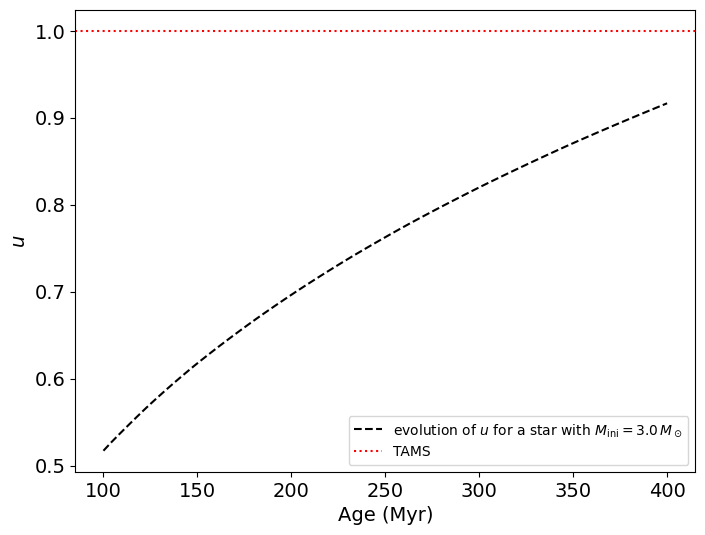

In [157]:
fz=14

plt.figure(figsize=(8, 6))
plt.plot(10**(logAges-6), us, ls='--', color='black', label=r'evolution of $u$ for a star with $M_{\rm ini}=3.0\,M_\odot$')
plt.xlabel('Age (Myr)', fontsize=fz)
plt.ylabel('$u$', fontsize=fz)
plt.axhline(y=1.0, label='TAMS',color='red', linestyle=':')
plt.legend(fontsize=10)
plt.tick_params(axis='both', labelsize=fz)
plt.savefig('evolution of u at Mini=3Msun.pdf', bbox_inches='tight', pad_inches=0.02)

In [349]:
!open .

In [192]:
df_SGB = PARSECv2_collect_data('/Users/ziyinggu/Downloads/omega0.80_output260868684462.dat.gz', label_list='all')

100%|██████████| 1/1 [00:12<00:00, 12.29s/it]


In [193]:
df_SGB['label'].unique()

array([0., 1., 2., 3., 4., 5., 6., 7.])

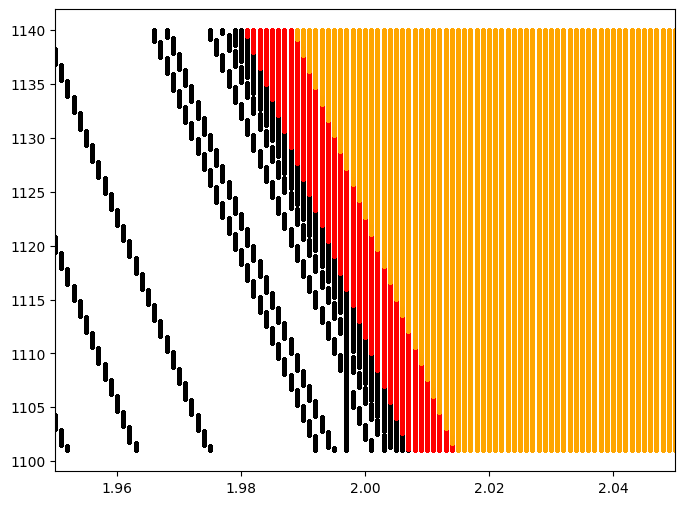

In [203]:
logAges = df_SGB['logAge'].unique()
s=4

SGB_min = []
SGB_max = []

plt.figure(figsize=(8, 6))

for logAge_i in logAges:
    # df_0i = df_SGB[(df_SGB['label'] == 0) & (df_SGB['logAge'] == logAge_i)]
    df_1i = df_SGB[(df_SGB['label'] == 1) & (df_SGB['logAge'] == logAge_i)]
    df_2i = df_SGB[(df_SGB['label'] == 2) & (df_SGB['logAge'] == logAge_i)]
    SGB_min.append(np.min(df_2i['Mini']))
    SGB_max.append(np.max(df_2i['Mini']))
    df_3i = df_SGB[(df_SGB['label'] >= 3) & (df_SGB['logAge'] == logAge_i)]
    # plt.scatter(df_0i['Mass'], np.ones_like(df_0i['Mass'])*10**(logAge_i-6), s=s, c='blue')
    plt.scatter(df_1i['Mass'], np.ones_like(df_1i['Mass'])*10**(logAge_i-6), s=s, c='black')
    plt.scatter(df_2i['Mass'], np.ones_like(df_2i['Mass'])*10**(logAge_i-6), s=s, c='red')
    plt.scatter(df_3i['Mass'], np.ones_like(df_3i['Mass'])*10**(logAge_i-6), s=s, c='orange')
plt.xlim([1.95, 2.05])
plt.show()

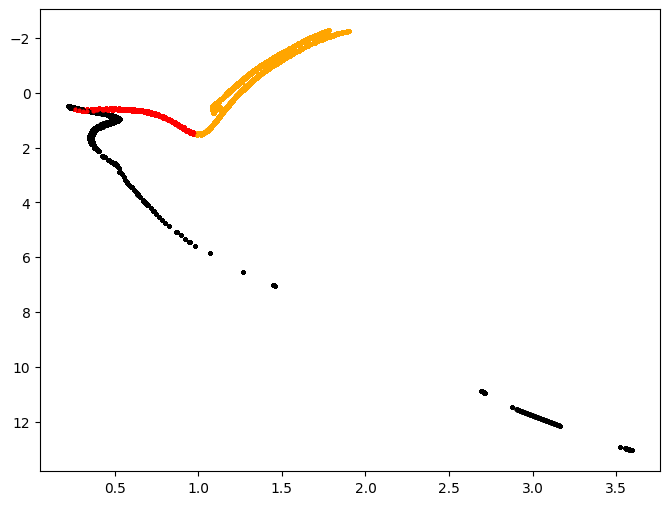

In [202]:
logAges = df_SGB['logAge'].unique()
s=4
Inclination = 0
plt.figure(figsize=(8, 6))

for logAge_i in logAges:
    # df_0i = df_SGB[(df_SGB['label'] == 0) & (df_SGB['logAge'] == logAge_i) & (df_SGB['Inclination'] == Inclination)]
    df_1i = df_SGB[(df_SGB['label'] == 1) & (df_SGB['logAge'] == logAge_i) & (df_SGB['Inclination'] == Inclination)]
    df_2i = df_SGB[(df_SGB['label'] == 2) & (df_SGB['logAge'] == logAge_i) & (df_SGB['Inclination'] == Inclination)]
    df_3i = df_SGB[(df_SGB['label'] >= 3) & (df_SGB['logAge'] == logAge_i) & (df_SGB['Inclination'] == Inclination)]
    # plt.scatter(df_0i['G_BP'] - df_0i['G_RP'], df_0i['G'], s=s, c='blue')
    plt.scatter(df_1i['G_BP'] - df_1i['G_RP'], df_1i['G'], s=s, c='black')
    plt.scatter(df_2i['G_BP'] - df_2i['G_RP'], df_2i['G'], s=s, c='red')
    plt.scatter(df_3i['G_BP'] - df_3i['G_RP'], df_3i['G'], s=s, c='orange')
# plt.xlim([1.95, 2.05])
plt.gca().invert_yaxis()
plt.show()

In [204]:
SGB_min_array = np.array(SGB_min)
SGB_max_array = np.array(SGB_max)

In [206]:
ages_array = 10**(logAges-6)

In [207]:
import numpy as np
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

# 已知点

# 创建一维线性插值函数
f_min = interp1d(SGB_min_array, ages_array, kind='linear')
f_max = interp1d(SGB_max_array, ages_array, kind='linear')

# 新的 x
x_new = 2

# 插值后的 y
y_min_new = f_min(x_new)
y_max_new = f_max(x_new)


In [208]:
y_min_new

array(1116.50327163)

In [209]:
y_max_new

array(1127.48299382)

In [259]:
interp_func([2.0, 8.0, 0.0, 0.8, 0.524])[:4]

array([[1.99992216, 0.77519666, 1.78960153, 1.58734285, 1.60644616,
        1.62349856, 1.57454135, 1.67054452, 1.64316357, 1.52953653,
        1.55244293, 1.53566667]])

In [263]:
import astropy.constants as ct
import astropy.units as u

In [266]:

print(vsini)

116.69393163462325


In [265]:
print(Mass, omega, Req, Rpol)

1.9999221563339233 0.775196659564972 1.7896015286445617 1.587342846393585


In [270]:
import astropy.constants as ct
import astropy.units as u

In [271]:
Mass, omega, Req, Rpol = interp_func([2.0, 8.0, 0.0, 0.8, 0.524])[:, :4].flatten()
omega_angular = omega * np.sqrt(ct.GM_sun*Mass/(ct.R_sun * 1.5 * Rpol)**3)
vtaneq = (omega_angular*Req*ct.R_sun).to('km/s').value
Inclination=0.524
vsini = vtaneq * np.sin(Inclination)
print(vsini)

116.69393163462325


In [281]:
import numpy as np
from scipy.stats import qmc
from scipy.spatial.distance import cdist

# ------------------------------------------------------------
# 0. Target values
# ------------------------------------------------------------

target_param = np.array([[2.0, 8.0, 0.0, 0.8, 0.524]])

mag_err = 0.02
vsini_err = 5.0  # km/s


def compute_vsini(params):
    outputs = interp_func(params)

    Mass = outputs[:, 0]
    omega = outputs[:, 1]
    Req = outputs[:, 2]
    Rpol = outputs[:, 3]

    omega_angular = omega * np.sqrt(
        ct.GM_sun * Mass / (ct.R_sun * 1.5 * Rpol) ** 3
    )

    vtaneq = (omega_angular * Req * ct.R_sun).to("km/s").value
    vsini = vtaneq * np.sin(params[:, 4])

    return vsini


obs_outputs = interp_func(target_param)
obs_mags = obs_outputs[:, 4:].ravel() + 5
vsini_obs = compute_vsini(target_param)[0]

print(f"Target vsini = {vsini_obs:.3f} km/s")


# ------------------------------------------------------------
# 1. Parameter ranges
#    Mass, logAge, [M/H], omega, inclination
# ------------------------------------------------------------

# bounds = np.array([
#     [2.1, 2.9],
#     [7.0, 9.0],
#     [-0.79, 0.34],
#     [0.0, 1.0],
#     [0.0, 1.527],
# ])

bounds = np.array([
    [1.9, 2.1],
    [7.0, 8.0],
    [-0.79, 0.34],
    [0.0, 1.0],
    [0, 1.527],
])

def sample_params(n_samples, seed=None):
    sampler = qmc.LatinHypercube(d=5, seed=seed)
    u = sampler.random(n_samples)
    return qmc.scale(u, bounds[:, 0], bounds[:, 1])


def evaluate_params(params):
    outputs = interp_func(params)

    mags = outputs[:, 4:] + 5
    residual = mags - obs_mags[None, :]

    chi2_phot = np.sum((residual / mag_err) ** 2, axis=1)

    vsini_model = compute_vsini(params)
    chi2_vsini = ((vsini_model - vsini_obs) / vsini_err) ** 2

    chi2 = chi2_phot + chi2_vsini

    max_abs_residual = np.max(np.abs(residual), axis=1)

    return mags, residual, chi2, max_abs_residual, vsini_model


# ------------------------------------------------------------
# 2. Search candidates
# ------------------------------------------------------------

all_good_params = []
all_good_chi2 = []
all_good_vsini = []

batch_size = 200000
max_batches = 50

for batch_i in range(max_batches):
    params = sample_params(batch_size, seed=batch_i)

    mags, residual, chi2, max_abs_residual, vsini_model = evaluate_params(params)

    # Require every photometric band within 0.02 mag
    # and vsini within 1 sigma.
    good = (
        (max_abs_residual <= mag_err)
        & (np.abs(vsini_model - vsini_obs) <= vsini_err)
    )

    if np.any(good):
        all_good_params.append(params[good])
        all_good_chi2.append(chi2[good])
        all_good_vsini.append(vsini_model[good])

    n_found = sum(len(x) for x in all_good_params)
    print(f"Batch {batch_i}: found {n_found} candidates")

    if n_found >= 1000:
        break


if len(all_good_params) == 0:
    raise RuntimeError("No candidates found. Try increasing max_batches or relaxing the selection criteria.")

good_params = np.vstack(all_good_params)
good_chi2 = np.concatenate(all_good_chi2)
good_vsini = np.concatenate(all_good_vsini)

print("Total candidates:", len(good_params))


# ------------------------------------------------------------
# 3. Select diverse solutions
#    Diversity is measured only in logAge, [M/H], omega, inclination.
#    Mass is excluded.
# ------------------------------------------------------------

def greedy_diverse_selection(params, scores, n_select=10):
    n_select = min(n_select, len(params))

    x = params[:, 1:]  # exclude mass

    x_norm = (x - bounds[1:, 0]) / (bounds[1:, 1] - bounds[1:, 0])

    selected = [np.argmin(scores)]
    min_dist = cdist(x_norm, x_norm[selected]).ravel()

    score_scale = np.nanmedian(scores)
    if not np.isfinite(score_scale) or score_scale <= 0:
        score_scale = 1.0

    while len(selected) < n_select:
        score = min_dist - 0.02 * (scores / score_scale)
        score[selected] = -np.inf

        idx = np.argmax(score)
        selected.append(idx)

        new_dist = cdist(x_norm, x_norm[[idx]]).ravel()
        min_dist = np.minimum(min_dist, new_dist)

    return np.array(selected)


selected_idx = greedy_diverse_selection(
    good_params,
    good_chi2,
    n_select=100,
)

selected_params = good_params[selected_idx]
selected_chi2 = good_chi2[selected_idx]
selected_vsini = good_vsini[selected_idx]


# Sort by chi2
order = np.argsort(selected_chi2)

selected_params = selected_params[order]
selected_chi2 = selected_chi2[order]
selected_vsini = selected_vsini[order]


# ------------------------------------------------------------
# 4. Output
# ------------------------------------------------------------

param_names = ["Mass", "logAge", "[M/H]", "omega", "inclination"]

for i, (p, c2, vsi) in enumerate(zip(selected_params, selected_chi2, selected_vsini)):
    print(
        f"{i:03d} | chi2={c2:.3f} | vsini={vsi:.3f} km/s | "
        + " | ".join(
            f"{name}={val:.5f}" for name, val in zip(param_names, p)
        )
    )

Target vsini = 116.694 km/s
Batch 0: found 9 candidates
Batch 1: found 19 candidates
Batch 2: found 40 candidates
Batch 3: found 55 candidates
Batch 4: found 70 candidates
Batch 5: found 90 candidates
Batch 6: found 108 candidates
Batch 7: found 122 candidates
Batch 8: found 142 candidates
Batch 9: found 153 candidates
Batch 10: found 177 candidates
Batch 11: found 194 candidates
Batch 12: found 209 candidates
Batch 13: found 228 candidates
Batch 14: found 244 candidates
Batch 15: found 261 candidates
Batch 16: found 278 candidates
Batch 17: found 287 candidates
Batch 18: found 304 candidates
Batch 19: found 331 candidates
Batch 20: found 339 candidates
Batch 21: found 358 candidates
Batch 22: found 371 candidates
Batch 23: found 387 candidates
Batch 24: found 414 candidates
Batch 25: found 429 candidates
Batch 26: found 441 candidates
Batch 27: found 452 candidates
Batch 28: found 466 candidates
Batch 29: found 486 candidates
Batch 30: found 506 candidates
Batch 31: found 520 candidat

In [ ]:
Mass=1.96626 | logAge=8.03069 | [M/H]=-0.10242 | omega=0.84810 | inclination=0.48523
Mass=1.91823 | logAge=8.64872 | [M/H]=-0.22988 | omega=0.58451 | inclination=1.00264
Mass=2.09810 | logAge=8.13890 | [M/H]=0.17013 | omega=0.44395 | inclination=1.52207
Mass=2.09792 | logAge=7.64649 | [M/H]=0.16894 | omega=0.55385 | inclination=0.83117




In [283]:
plot_params = np.array([
    [1.96626, 8.03069, -0.10242, 0.84810, 0.48523],
    [1.91823, 8.64872, -0.22988, 0.58451, 1.00264],
    [2.09810, 8.13890, 0.17013, 0.44395, 1.52207],
    [2.09792, 7.64649, 0.16894, 0.55385, 0.83117]
])

In [290]:
vsini

array([132.19368117, 149.67554416,  25.71770287,  80.44977115,
       112.99198385])

In [278]:
np.where(selected_params[:, -1]<np.deg2rad(40))

(array([], dtype=int64),)

In [228]:
(interp_func([2.0, 8.0, 0.0, 0.8, 0.524])[:, 4:] + 5).shape

(1, 8)

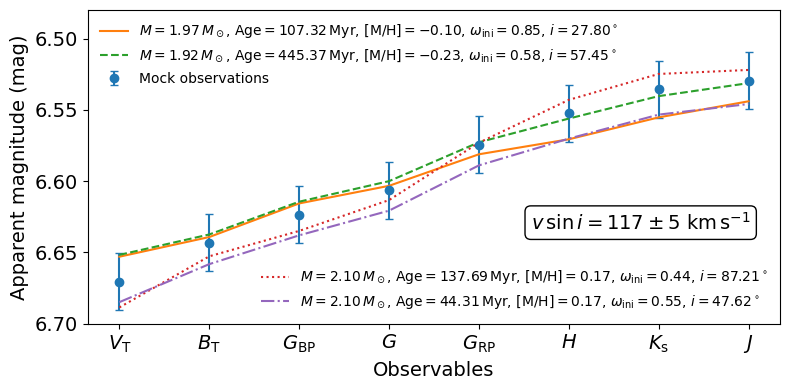

In [334]:
import numpy as np
import matplotlib.pyplot as plt

bands = np.array([
    "$G$", r"$G_{\rm BP}$", r"$G_{\rm RP}$", r"$V_{\rm T}$",
    r"$B_{\rm T}$", "$J$", "$H$", r"$K_{\rm s}$", r"$v \sin i$"
])

# Model magnitudes
mags = interp_func(
    [2.0, 8.0, 0.0, 0.8, 0.524]
)[:, 4:].flatten() + 5


Mass, omega, Req, Rpol = interp_func([2.0, 8.0, 0.0, 0.8, 0.524])[:, :4].flatten()
omega_angular = omega * np.sqrt(ct.GM_sun*Mass/(ct.R_sun * 1.5 * Rpol)**3)
vtaneq = (omega_angular*Req*ct.R_sun).to('km/s').value
Inclination=0.524
vsini = vtaneq * np.sin(Inclination)
# print(vsini)

mag_err = np.full_like(mags, 0.02)

# Sort by magnitude (bright -> faint)
order = np.argsort(mags)[::-1]

mags_sorted = mags[order]
# final_sorted = np.append(mags_sorted, vsini)
mag_err_sorted = mag_err[order]
# final_err_sorted = np.append(mag_err_sorted, 5)
bands_sorted = bands[order]

# Equal spacing on x-axis
x = np.arange(len(bands_sorted))

plt.figure(figsize=(8, 4))

plt.errorbar(
    x,
    mags_sorted,
    yerr=mag_err_sorted,
    fmt="o",
    capsize=3,
    linestyle="none",
    label=r"Mock observations",
)

ls = ['-', '--', ':', '-.']

for j in [0, 1, 2, 3]:
    solution = plot_params[j]
    solution_mags = interp_func(solution)[:, 4:].flatten() + 5
    Mass, omega, Req, Rpol = interp_func(solution)[:, :4].flatten()
    omega_angular = omega * np.sqrt(ct.GM_sun*Mass/(ct.R_sun * 1.5 * Rpol)**3)
    vtaneq = (omega_angular*Req*ct.R_sun).to('km/s').value
    Inclination=plot_params[-1]
    vsini = vtaneq * np.sin(Inclination)
    solution_mags_sorted = solution_mags[order]
    final_mags_sorted = np.append(solution_mags_sorted, vsini)

    plt.plot(
        x,
        solution_mags_sorted,
        ls=ls[j],
        label=(
            rf"$M={plot_params[j][0]:.2f}\,M_\odot$, "
            rf"$\mathrm{{Age}}={10**(plot_params[j][1]-6):.2f}\,\mathrm{{Myr}}$, "
            rf"$\mathrm{{[M/H]}}={plot_params[j][2]:.2f}$, "
            rf"$\omega_{{\rm ini}}={plot_params[j][3]:.2f}$, "
            rf"$i={np.rad2deg(plot_params[j][4]):.2f}^\circ$"
        )
    )


ax = plt.gca()

ax.text(
    0.64, 0.3,
    r"$v\,\sin i = 117 \pm 5\ \mathrm{km\,s^{-1}}$",
    transform=ax.transAxes,
    fontsize=14,
    bbox=dict(
        facecolor="white",
        edgecolor="black",
        boxstyle="round,pad=0.3"
    )
)


plt.ylim([6.48, 6.70])
plt.xticks(x, bands_sorted)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("Observables", fontsize=14)
plt.ylabel("Apparent magnitude (mag)", fontsize=14)

# Astronomical convention
plt.gca().invert_yaxis()
ax = plt.gca()
ax.set_yticks([6.50, 6.55, 6.60, 6.65, 6.70])
handles, labels = ax.get_legend_handles_labels()

mid = len(handles) // 2

idx1 = [ 0, 1, -1]
idx2 = [2, 3]

leg1 = ax.legend(
    [handles[i] for i in idx1],
    [labels[i] for i in idx1],
    loc="upper left",
    fontsize=10,
    frameon=False,
)

ax.add_artist(leg1)

ax.legend(
    [handles[i] for i in idx2],
    [labels[i] for i in idx2],
    loc="lower right",
    fontsize=10,
    frameon=False,
)

plt.tight_layout()

plt.savefig("rotation_effect.pdf")
plt.show()

In [331]:
handles

 <ErrorbarContainer object of 3 artists>]

In [351]:
df.columns

Index(['Zini', 'MH', 'logAge', 'Mini', 'int_IMF', 'Mass', 'logL', 'logTe',
       'logg', 'label', 'McoreTP', 'C_O', 'period0', 'period1', 'period2',
       'period3', 'period4', 'pmode', 'Mloss', 'tau1m', 'X', 'Y', 'Xc', 'Xn',
       'Xo', 'Cexcess', 'Z', 'Teff0', 'omega_ini', 'omega', 'omega_k',
       'angvel', 'vtaneq', 'vsini', 'angmom', 'Rpol', 'Req', 'mbolmag',
       'G_fSBmag', 'G_BP_fSBmag', 'G_RP_fSBmag', 'G_fSB', 'G_f0', 'G_fk',
       'G_BP_fSB', 'G_BP_f0', 'G_BP_fk', 'G_RP_fSB', 'G_RP_f0', 'G_RP_fk',
       'Inclination_deg', 'Inclination', 'G', 'G_BP', 'G_RP'],
      dtype='object')

In [353]:
df_non_rot_teff = PARSECv2_collect_data('/Users/ziyinggu/Programming/Projects/RotAge-BAF/data/isochrones/100e6_2000e6yr_linear_isochrones_rearranged (2mass & tycho2 & gaia dr3)/omega0.00_linear_age100e6to2000e6d60e6_MH-0.79to0.31d0.1 (2mass & tycho2 & gaia dr3).dat')

100%|██████████| 1/1 [00:24<00:00, 24.64s/it]


In [354]:
df_0d8_teff = PARSECv2_collect_data('/Users/ziyinggu/Programming/Projects/RotAge-BAF/data/isochrones/100e6_2000e6yr_linear_isochrones_rearranged (2mass & tycho2 & gaia dr3)/omega0.80_linear_age100e6to2000e6d60e6_MH-0.79to0.31d0.1 (2mass & tycho2 & gaia dr3).dat')

100%|██████████| 1/1 [00:21<00:00, 21.84s/it]


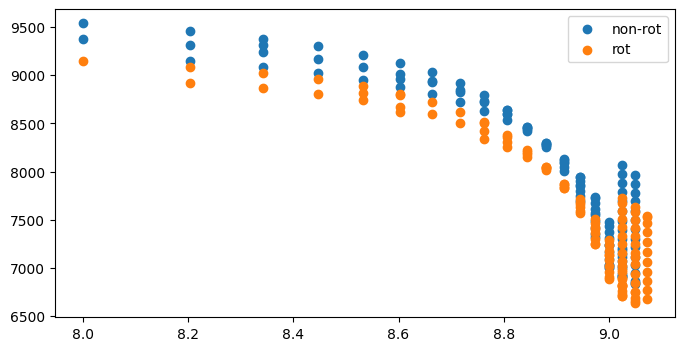

In [359]:
plt.figure(figsize=(8, 4))

df0 = df_non_rot_teff[(df_non_rot_teff['MH']==0.01) & (df_non_rot_teff['Inclination']==0.0) & (df_non_rot_teff['Mass']>1.95) & (df_non_rot_teff['Mass']<2.05)]
df08 = df_0d8_teff[(df_0d8_teff['MH']==0.01) & (df_0d8_teff['Inclination']==0.0) & (df_0d8_teff['Mass']>1.95) & (df_0d8_teff['Mass']<2.05)]

plt.scatter(df0['logAge'], 10**df0['logTe'], label='non-rot')
plt.scatter(df08['logAge'], 10**df08['logTe'], label='rot')
plt.legend()

In [357]:
df0 = df_non_rot_teff[(df_non_rot_teff['MH']==0.01) & (df_non_rot_teff['Inclination']==0.0)].copy()
df08 = df_0d8_teff[(df_0d8_teff['MH']==0.01) & (df_0d8_teff['Inclination']==0.0) ].copy()

/var/folders/xc/rw1jkm1x0_1bhxz5h8s2_d200000gn/T/ipykernel_67311/672732753.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df08 = df_non_rot_teff[(df_0d8_teff['MH']==0.01) & (df_0d8_teff['Inclination']==0.0) ].copy()


In [425]:
from glob import glob
from pathlib import Path
import re


In [428]:
rows = []

paths = (glob('/Users/ziyinggu/Programming/Projects/belfast-astro/results/Hyades_PARS_results/*/*.npz') +
         glob('/Users/ziyinggu/Programming/Projects/belfast-astro/results/Praesepe_PARS_results/*/*.npz') +
         glob('/Users/ziyinggu/Programming/Projects/belfast-astro/results/Pleiades_PARS_results/*/*.npz'))

# paths = (glob('/Users/ziyinggu/Programming/Projects/belfast-astro/results/Hyades_DIRECT_results/*/*.npz') +
#          glob('/Users/ziyinggu/Programming/Projects/belfast-astro/results/Praesepe_DIRECT_results/*/*.npz') +
#          glob('/Users/ziyinggu/Programming/Projects/belfast-astro/results/Pleiades_DIRECT_results/*/*.npz'))

for i in range(len(paths)):

    path = Path(paths[i])
    folder = path.parts[-3]

    cluster, method, _ = folder.split("_", 2)

    stem = path.stem.replace("posterior_", "")

    m = re.match(
        rf"(.+?)_{re.escape(cluster)}_{re.escape(method)}",
        stem
    )

    target_name = m.group(1).replace("_", " ")

    data = np.load(paths[i])
    samples = data["samples"]
    n_discard = int(data["n_discard"])

    samples_burnt = samples[n_discard:, :, :]
    flat_samples = samples_burnt.reshape(-1, samples_burnt.shape[-1])

    u = interp_u(flat_samples[:, :5])
    u = np.asarray(u).ravel()
    u = u[np.isfinite(u)]

    # 3σ, 2σ, 1σ, median, 1σ, 2σ, 3σ percentiles
    p0013, p0228, p1587, p5000, p8413, p9772, p9987 = np.percentile(
        u,
        [0.13, 2.28, 15.87, 50.0, 84.13, 97.72, 99.87]
    )

    rows.append({
        "cluster": cluster,
        "target name": target_name,
        "METHOD": method,
        "u_p0.13": p0013,
        "u_p2.28": p0228,
        "u_p15.87": p1587,
        "u_p50": p5000,
        "u_p84.13": p8413,
        "u_p97.72": p9772,
        "u_p99.87": p9987,
    })

df_u = pd.DataFrame(rows)

df_u

,cluster,target name,METHOD,u_p0.13,u_p2.28,u_p15.87,u_p50,u_p84.13,u_p97.72,u_p99.87
0,Hyades,HIP 22044,PARS,0.570843,0.622889,0.717437,0.775042,0.807476,0.834258,0.853747
1,Hyades,HIP 18735,PARS,0.280115,0.348942,0.488013,0.608440,0.716332,0.764775,0.797824
2,Hyades,HIP 18170,PARS,0.422564,0.538714,0.663966,0.715333,0.750595,0.780397,0.808970
3,Hyades,HIP 20635,PARS,0.821794,0.845711,0.882286,0.913860,0.929511,0.940265,0.949964
4,Hyades,HIP 21036,PARS,0.609239,0.680192,0.755226,0.794664,0.822746,0.845134,0.865789
5,Hyades,HIP 20641,PARS,0.634323,0.669757,0.709303,0.758585,0.802981,0.836278,0.863028
6,Hyades,HIP 23497,PARS,0.819195,0.839837,0.869985,0.891302,0.904873,0.914692,0.924817
7,Hyades,HIP 21670,PARS,0.581935,0.649775,0.730337,0.775697,0.806615,0.835191,0.861578
8,Hyades,HIP 20261,PARS,0.645133,0.696784,0.772258,0.811909,0.837796,0.859720,0.879280
9,Praesepe,HD 73818,PARS,0.354417,0.467600,0.556272,0.642632,0.709198,0.757487,0.798546


In [427]:
# df_u.to_csv('DIRECT.csv', index=False)

In [429]:
df_u.to_csv('PARS.csv', index=False)

In [444]:
np.sqrt(ct.GM_sun*6.07/(ct.R_sun * 12))

<Quantity 310633.67725208 m / s>

In [557]:
import astropy.constants as ct
import astropy.units as u

v_keplerian = np.sqrt(ct.GM_sun*6.07/(ct.R_sun * 12))
vtaneq = 225 / np.sin(np.deg2rad(50))
omega = vtaneq/v_keplerian.to('km/s').value
print(omega)



0.9455402347164334


In [558]:
1000/23.39 * u.pc.to('cm')

1.3192294063665527e+20

In [442]:
from pa.lib import star

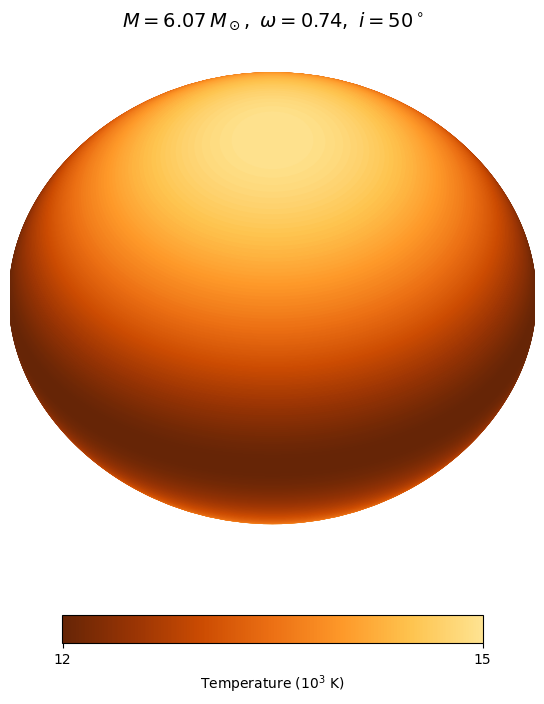

In [454]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

from pa.lib import star

# ============================================================
# Stellar parameters
# ============================================================

omega = 0.946

mass = 6.07                      # Msun
luminosity = 10**3.5             # Lsun

Req = 12.0                       # Rsun

parallax_mas = 23.39
distance_pc = 1000.0 / parallax_mas
distance_cm = distance_pc * 3.085677581e18

inclination = np.deg2rad(50.0)

nz = 100

# ============================================================
# Kurucz limb-darkening file
# ============================================================

ld_file = "/Users/ziyinggu/Programming/Projects/RotAge-BAF/data/Kurucz_limb_darkening/limdark_m01.pkl"

with open(ld_file, "rb") as f:
    ld = pickle.load(f)

# ============================================================
# Build star
# ============================================================

st = star.Star(
    omega=omega,
    luminosity=luminosity,
    mass=mass,
    Req=Req,
    distance=distance_cm,
    nz=nz,
    ld=ld,
    temp_method="planck",
    g_method="log",
    nm=15,
)

# ============================================================
# Plot
# ============================================================

fig = plt.figure(figsize=(7, 7))

ax = fig.add_axes([0.10, 0.20, 0.80, 0.75])
cax = fig.add_axes([0.20, 0.08, 0.60, 0.04])

st.plot_temp(
    ax=ax,
    inclination=inclination,
    size_inches=5,
    cax=cax,
    exp=3,
)

ax.set_title(
    rf"$M={mass:.2f}\,M_\odot,\ "
    rf"\omega={omega:.2f},\ "
    rf"i={np.rad2deg(inclination):.0f}^\circ$",
    fontsize=14,
)

plt.show()

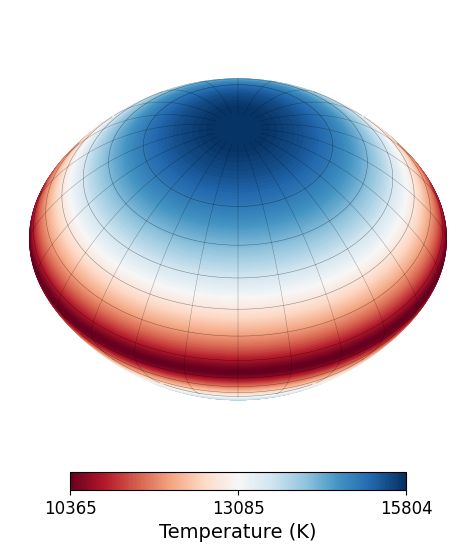

In [604]:
import pickle
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from pa.lib import star


# ============================================================
# Input parameters
# ============================================================

omega = 0.946
mass = 6.0                 # Msun
luminosity = 10**3.5        # Lsun
Req = 12.0                  # Rsun

parallax_mas = 23.39
distance_pc = 1000.0 / parallax_mas
distance_cm = distance_pc * 3.085677581e18

inclination = np.deg2rad(50.0)
nz = 100

ld_file = "/Users/ziyinggu/Programming/Projects/RotAge-BAF/data/Kurucz_limb_darkening/limdark_m01.pkl"

with open(ld_file, "rb") as f:
    ld = pickle.load(f)


# ============================================================
# Build star model
# ============================================================

st = star.Star(
    omega=omega,
    luminosity=luminosity,
    mass=mass,
    Req=Req,
    distance=distance_cm,
    nz=nz,
    ld=ld,
    temp_method="planck",
    g_method="log",
    nm=15,
)


# ============================================================
# Custom temperature plot with visible grid only
# ============================================================

def plot_temp_rdbu_with_visible_grid(
    st,
    ax,
    inclination,
    size_inches,
    cax=None,
    n_lat=12,
    n_lon=24,
):
    sine = np.sin(inclination)
    cosn = np.cos(inclination)

    st.surface.set_inclination(inclination)

    z_up = st.map.z_up
    z_surf_full = np.concatenate((-1 * np.flip(z_up)[:-1], z_up))

    r_full = st.surface.R(z_surf_full)
    z_plot_full = z_surf_full / st.surface.f

    r_diff = np.diff(r_full)
    z_diff = np.diff(z_plot_full)
    line_width_req = 2 * (r_diff * cosn + z_diff * sine)

    r = r_full[1:]
    z_plot = z_plot_full[1:]
    z_surf = z_surf_full[1:]

    b = r * cosn
    c = z_plot * sine

    T_up = st.map.temp_up
    T = np.concatenate((np.flip(T_up)[:-1], T_up))[1:]

    T_min = np.nanmin(T)
    T_max = np.nanmax(T)

    norm = mpl.colors.Normalize(vmin=T_min, vmax=T_max)
    cmap = mpl.cm.RdBu

    size_req = 2.0
    inch_per_req = size_inches / size_req
    point_per_req = inch_per_req * 72.0

    ax.set_aspect(1)
    ax.axis("off")
    ax.set_frame_on(False)
    ax.set_xlim([-1.1, 1.1])
    ax.set_ylim([-1.1, 1.1])
    # ax.set_xlim([-0.9, 0.9])
    # ax.set_ylim([-0.9, 0.9])
    # --------------------------------------------------------
    # Temperature-colored surface
    # --------------------------------------------------------
    for i in range(len(z_plot)):
        color = cmap(norm(T[i]))

        ellipse = mpl.patches.Ellipse(
            xy=(0, c[i]),
            width=2 * r[i],
            height=2 * b[i],
            edgecolor=color,
            facecolor=color,
            fill=True,
            lw=point_per_req * line_width_req[i],
        )
        ax.add_patch(ellipse)

    # --------------------------------------------------------
    # Visible latitude lines only
    # --------------------------------------------------------
    lat_idx = np.linspace(0, len(z_plot) - 1, n_lat + 2, dtype=int)[1:-1]
    phi_dense = np.linspace(0, 2 * np.pi, 600)

    for i in lat_idx:
        a_i, b_i = st.surface.ab(np.array([z_surf[i]]))
        mu = a_i[0] * np.cos(phi_dense) + b_i[0]
        visible = mu < 0

        y_lat = r[i] * np.sin(phi_dense)
        x_lat = r[i] * np.cos(phi_dense) * cosn - z_plot[i] * sine

        y_lat = np.where(visible, y_lat, np.nan)
        x_lat = np.where(visible, x_lat, np.nan)

        ax.plot(
            y_lat,
            x_lat,
            color="black",
            lw=0.35,
            alpha=0.45,
        )

    # --------------------------------------------------------
    # Visible longitude lines only
    # --------------------------------------------------------
    phi_list = np.linspace(0, 2 * np.pi, n_lon, endpoint=False)

    a_mu, b_mu = st.surface.ab(z_surf)

    for phi in phi_list:
        cos_phi = np.cos(phi)
        mu = a_mu * cos_phi + b_mu
        visible = mu < 0

        y_lon = r * np.sin(phi)
        x_lon = r * np.cos(phi) * cosn - z_plot * sine

        y_lon = np.where(visible, y_lon, np.nan)
        x_lon = np.where(visible, x_lon, np.nan)

        ax.plot(
            y_lon,
            x_lon,
            color="black",
            lw=0.35,
            alpha=0.35,
        )

    # --------------------------------------------------------
    # Colorbar
    # --------------------------------------------------------
    if cax is not None:
        cb = mpl.colorbar.ColorbarBase(
            cax,
            cmap=cmap,
            norm=norm,
            orientation="horizontal",
            ticks=ticker.LinearLocator(3),
            format="%.0f",
        )
        cb.set_label(
            "Temperature (K)",
            fontsize=14,
        )

        cb.ax.tick_params(
            labelsize=12
        )


# ============================================================
# Plot
# ============================================================

fig = plt.figure(figsize=(6, 6))

ax = fig.add_axes([0.08, 0.18, 0.84, 0.76])

cax = fig.add_axes([0.22, 0.14, 0.56, 0.03])

plot_temp_rdbu_with_visible_grid(
    st=st,
    ax=ax,
    inclination=inclination,
    size_inches=6,
    cax=cax,
    n_lat=12,
    n_lon=24,
)

# ax.set_title(
#     rf"$\mathrm{{Achernar}}: \omega_{{\rm k}}={omega:.2f}$, $i={np.rad2deg(inclination):.0f}^\circ$",
#     fontsize=14,
# )

plt.savefig("Achernar_surface.pdf", bbox_inches="tight", dpi=300)
plt.show()

In [505]:
from lib.target_utils import cal_abs_mag

In [508]:
Achernar_model = np.zeros([91, 3])
Achernar_model_abs = np.zeros([91, 3])

for i in range(91):

    st = star.Star(
        omega=omega,
        luminosity=luminosity,
        mass=mass,
        Req=Req,
        distance=distance_cm,
        nz=nz,
        ld=ld,
        temp_method="planck",
        g_method="log",
        nm=15,
    )

    original_mags = st.integrate(np.deg2rad(i))
    rearranged_mags = original_mags[[3, 4, 5, 6, 7, 1, 0, 2]]

    Achernar_model[i, :] = rearranged_mags[:3]
    Achernar_model_abs[i, :] = cal_abs_mag(rearranged_mags[:3], 0, 23.39, 0, 0)[0]

In [503]:
Achernar_model_abs = cal_abs_mag(rearranged_mags[:3], 0, 23.39, 0, 0)[0]

In [480]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [482]:
df_pleiades = pd.read_csv('/Users/ziyinggu/Data/AgeEstimationBeta/membership/pleiades_data.csv')
df_hyades = pd.read_csv('/Users/ziyinggu/Data/AgeEstimationBeta/membership/hyades_data.csv')

In [483]:
from astroquery.gaia import Gaia
import pandas as pd

# 你的 df，假设 df["source_id"] 存储 Gaia DR3 的 source_id
source_ids = df_pleiades["SourceCP"].astype(str).tolist()

# 把ID拼成 SQL IN 结构
id_list = ",".join(source_ids)

query = f"""
SELECT
    source_id,
    parallax,
    phot_g_mean_mag,
    phot_bp_mean_mag,
    phot_rp_mean_mag
FROM gaiadr3.gaia_source
WHERE source_id IN ({id_list})
"""

# 启动查询
job = Gaia.launch_job_async(query)
result = job.get_results()

# 转成 pandas
df_pleiades_gaia = result.to_pandas()

print(df_pleiades_gaia.head())
print("Total rows:", len(df_pleiades_gaia))


In preparation for Gaia DR4, the Gaia archive is in evolution. Unfortunately, it may be unstable at times and particular types of queries may time out. Please consider registering for a user account (https://www.cosmos.esa.int/web/gaia-users/register). For questions or advice, please contact the Gaia helpdesk (https://www.cosmos.esa.int/web/gaia/gaia-helpdesk).
INFO: Query finished. [astroquery.utils.tap.core]
            source_id  parallax  phot_g_mean_mag  phot_bp_mean_mag  \
0  116903344738559744  7.716659        18.828989         20.768059   
1   47048106850285824  7.200826        16.066448         17.644253   
2   50437690743214592  4.013060        20.657312         21.096502   
3   51323901410617088  4.076879        20.843985         21.597208   
4   51391658816356608  7.614944        16.933390         18.788616   

   phot_rp_mean_mag  
0         17.453661  
1         14.833865  
2         19.379395  
3         19.552467  
4         15.647491  
Total rows: 2215


In [484]:
df_pleiades_gaia = df_pleiades_gaia[df_pleiades_gaia["parallax"] > 0].copy()
df_pleiades_gaia["M_G"]  = df_pleiades_gaia["phot_g_mean_mag"]  + 5 * np.log10(df_pleiades_gaia["parallax"]) - 10
df_pleiades_gaia["M_BP"] = df_pleiades_gaia["phot_bp_mean_mag"] + 5 * np.log10(df_pleiades_gaia["parallax"]) - 10
df_pleiades_gaia["M_RP"] = df_pleiades_gaia["phot_rp_mean_mag"] + 5 * np.log10(df_pleiades_gaia["parallax"]) - 10

In [485]:
from astroquery.gaia import Gaia
import pandas as pd

# 你的 df，假设 df["source_id"] 存储 Gaia DR3 的 source_id
source_ids = df_hyades["ID"].astype(str).tolist()

# 把ID拼成 SQL IN 结构
id_list = ",".join(source_ids)

query = f"""
SELECT
    source_id,
    parallax,
    phot_g_mean_mag,
    phot_bp_mean_mag,
    phot_rp_mean_mag
FROM gaiadr3.gaia_source
WHERE source_id IN ({id_list})
"""

# 启动查询
job = Gaia.launch_job_async(query)
result = job.get_results()

# 转成 pandas
df_hyades_gaia = result.to_pandas()

print(df_hyades_gaia.head())
print("Total rows:", len(df_hyades_gaia))

INFO: Query finished. [astroquery.utils.tap.core]
            source_id   parallax  phot_g_mean_mag  phot_bp_mean_mag  \
0  139587025532626048  12.014408        13.969216         15.251272   
1  244553655427661312  10.674813        15.913651         17.445488   
2  248560172722389504  15.970175        15.000232         16.686865   
3  254422631276673536  13.261981        19.940365         21.374262   
4  270660528238516352  12.594250         5.388618          5.521224   

   phot_rp_mean_mag  
0         12.848938  
1         14.708689  
2         13.752209  
3         18.283398  
4          5.163862  
Total rows: 1677


In [486]:
df_hyades_gaia = df_hyades_gaia[df_hyades_gaia["parallax"] > 0].copy()
df_hyades_gaia["M_G"]  = df_hyades_gaia["phot_g_mean_mag"]  + 5 * np.log10(df_hyades_gaia["parallax"]) - 10
df_hyades_gaia["M_BP"] = df_hyades_gaia["phot_bp_mean_mag"] + 5 * np.log10(df_hyades_gaia["parallax"]) - 10
df_hyades_gaia["M_RP"] = df_hyades_gaia["phot_rp_mean_mag"] + 5 * np.log10(df_hyades_gaia["parallax"]) - 10

In [487]:
from lib.isochrone_utils import read_isochrones

In [489]:
iso_pleiades = read_isochrones('/Users/ziyinggu/Downloads/Pleiades_150Myr_MH+0.01_omega0.0.dat')
iso_hyades = read_isochrones('/Users/ziyinggu/Downloads/Hyades_750Myr_MH+0.09_omega0.0.dat')

Reading lines: 100%|█████████▉| 312/313 [00:00<00:00, 38810.81it/s]


The number of isochrones: 1


Reading lines: 100%|█████████▉| 535/536 [00:00<00:00, 36730.11it/s]

The number of isochrones: 1


In [490]:
Hyades_G = iso_hyades[0]['G_i00'].values
Hyades_G_BP = iso_hyades[0]['G_BP_i00'].values
Hyades_G_RP = iso_hyades[0]['G_RP_i00'].values

Pleiades_G = iso_pleiades[0]['G_i00'].values
Pleiades_G_BP = iso_pleiades[0]['G_BP_i00'].values
Pleiades_G_RP = iso_pleiades[0]['G_RP_i00'].values

R_V = 3.16
A_G_over_A_V = 0.789
A_G_BP_over_A_V = 1.002
A_G_RP_over_A_V = 0.589
EB_V_Pleiades = 0.034

Pleiades_G_e = Pleiades_G + EB_V_Pleiades * R_V * A_G_over_A_V
Pleiades_G_BP_e = Pleiades_G_BP + EB_V_Pleiades * R_V * A_G_BP_over_A_V
Pleiades_G_RP_e = Pleiades_G_RP + EB_V_Pleiades * R_V * A_G_RP_over_A_V

In [527]:
# ------------------------------------------------------------
# Mock star sequence with inclination
# ------------------------------------------------------------
mock_star_abs_mags = np.zeros([91, 3])
inclinations_deg = np.arange(91)

for i in inclinations_deg:
    Inc = np.deg2rad(i)
    mock_star_abs_mags[i, :] = interp_func([2, 8, 0, 0.8, Inc])[0][4:7]

mock_color = mock_star_abs_mags[:, 1] - mock_star_abs_mags[:, 2]
mock_MG = mock_star_abs_mags[:, 0]


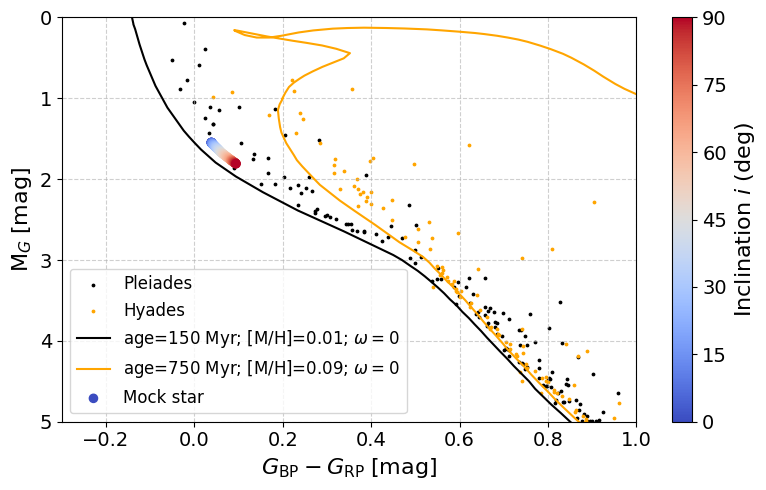

In [556]:
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# CMD
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    df_pleiades_gaia["phot_bp_mean_mag"] - df_pleiades_gaia["phot_rp_mean_mag"],
    df_pleiades_gaia["M_G"],
    label="Pleiades",
    s=3,
    c="black",
)

ax.scatter(
    df_hyades_gaia["phot_bp_mean_mag"] - df_hyades_gaia["phot_rp_mean_mag"],
    df_hyades_gaia["M_G"],
    label="Hyades",
    s=3,
    c="orange",
)

ax.plot(
    Pleiades_G_BP - Pleiades_G_RP,
    Pleiades_G,
    label=r"age=150 Myr; [M/H]=0.01; $\omega=0$",
    c="black",
)

ax.plot(
    Hyades_G_BP - Hyades_G_RP,
    Hyades_G,
    label=r"age=750 Myr; [M/H]=0.09; $\omega=0$",
    c="orange",
)

# Inclination-colored mock points
sc = ax.scatter(
    mock_color,
    mock_MG,
    c=inclinations_deg,
    cmap="coolwarm",
    vmin=0,
    vmax=90,
    s=35,
    # edgecolor="black",
    # linewidth=0.3,
    label="Mock star",
    zorder=5,
)

cbar = fig.colorbar(
    sc,
    ax=ax,
    ticks=[0, 15, 30, 45, 60, 75, 90],   # 稀疏刻度
)

cbar.set_label(
    r"Inclination $i$ (deg)",
    fontsize=16,             # colorbar标题字号
)

cbar.ax.tick_params(
    labelsize=14             # colorbar刻度字号
)

ax.set_xlim([-0.3, 1.])
ax.set_ylim([0, 5])
ax.invert_yaxis()

ax.grid(True, linestyle="--", alpha=0.6)

ax.set_xlabel(r"$G_{\mathrm{BP}} - G_{\mathrm{RP}} \;[\mathrm{mag}]$", fontsize=16)
ax.set_ylabel(r"$\mathrm{M}_G \;[\mathrm{mag}]$", fontsize=16)
ax.tick_params(
    axis="both",
    labelsize=14,
)
ax.legend(loc="lower left", fontsize=12)

plt.tight_layout()
plt.savefig("CMD_rot_star.pdf", bbox_inches="tight")
plt.show()

In [536]:
! open .

In [678]:
interp_u([1.7, np.log10(1000)+6, -0.7, 0.8, 0.524])

np.float64(0.9161891700292408)

In [679]:
interp_func([1.7, np.log10(1000)+6, -0.7, 0.8, 0.524])[0][-8:]+5

array([6.39564342, 6.41897445, 6.35007045, 6.46470548, 6.43886899,
       6.28006102, 6.29319361, 6.27539361])

In [680]:
interp_func([1.7, np.log10(1000)+6, -0.7, 0.8, 0.524])[0][:-8]

array([1.69666266, 0.77948767, 2.06447399, 1.82778859])

In [684]:
omega_cri = np.sqrt(ct.GM_sun*1.69666266 / (1.5 * ct.R_sun * 1.82778859)**3)
omega_cri * 0.77948767 * 2.06447399 * ct.R_sun.to('km') * 0.5

<Quantity 100.83363063 km / s>

In [681]:
interp_func([2, np.log10(900)+6, 0., 0.8, 0.524])[0][:-8]

array([1.99796131, 0.71080087, 2.97298774, 2.70420658])

In [682]:
omega_cri = np.sqrt(ct.GM_sun*1.99796131 / (1.5 * ct.R_sun * 2.7)**3)

In [683]:
omega_cri * 0.71080087 * 2.70420658 * ct.R_sun.to('km') * 0.5

<Quantity 72.79702607 km / s>

In [610]:
139*0.5

69.5

In [687]:
omega_cri * 0.77080087 * 2.060420658 * ct.R_sun.to('km') * 0.5

<Quantity 99.51414842 km / s>